# Diabetes Classification with the CDC BRFSS 2015 Health Indicators
### Traditional Machine Learning (Scikit-Learn) vs Deep Learning (TensorFlow / Keras)

**Research question.** Can self-reported health indicators and demographics (age, BMI, smoking, blood pressure, general health, income, ...) be used to screen for diabetes, and does a neural network trained with TensorFlow/Keras outperform well-tuned traditional machine-learning models on this tabular problem?

**Objectives**
1. Validate and explore a real dataset (CDC BRFSS 2015, > 250,000 survey records).
2. Build traditional models: Logistic Regression, Random Forest, HistGradientBoosting (a fast Gradient Boosting) and an RBF-kernel SVM.
3. Build a Keras neural network (Functional API) fed by a `tf.data` pipeline.
4. Run several experiments: feature engineering, class weighting, hyperparameter tuning (`RandomizedSearchCV`), and neural-network configuration comparison. All experiments are collected in one table (Section 14.1) and the networks are logged with TensorBoard and Weights & Biases in offline mode (Section 9.0).
5. Evaluate rigorously: precision, recall, F1, confusion matrices, ROC-AUC, precision-recall curves, learning curves, feature importance.
6. Select models on **validation** data only, then report once on a held-out **test** set.

**Hypotheses** (to be confirmed or rejected by the results you compute, not assumed)
- H1: Tuned gradient boosting will match or beat a baseline Logistic Regression on ROC-AUC.
- H2: A neural network will perform *comparably* to gradient boosting on this tabular data, rather than clearly better.
- H3: Because positives are a minority, a default 0.5 threshold gives low recall, and a validation-tuned threshold will improve screening-relevant recall.
- H4: Engineered features (e.g. cardiovascular risk count, BMI x Age) give at most a small gain for tree models.

> **Disclaimer.** This is an educational project. The models are *not* clinical diagnostic tools.

---
### How to use this notebook
1. Upload it to Google Colab (File -> Upload notebook) and run the cells **top to bottom**.
2. Make sure the dataset CSV is in your Google Drive (see Section 3 for how the file is located).
3. Quick smoke test: set `FAST_RUN = True` in Section 2 (runs in a few minutes on a subsample). Set it back to `False` for the real results.
4. For faster training, choose *Runtime -> Change runtime type -> GPU* (optional; most of the work is on CPU anyway).

## 2. Imports, configuration and reproducibility

Everything you might want to change is in the **configuration cell**. Random seeds are fixed for Python, NumPy and TensorFlow. Note that exact bit-for-bit reproducibility of neural-network results can still vary slightly across hardware (CPU vs GPU) and library versions, so the package versions are saved at the end.

In [34]:
import os, sys, json, time, random, warnings, zipfile, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown
from scipy.stats import loguniform, randint, uniform

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [35]:
# =====================  CONFIGURATION  =====================
SEED = 42

# True  -> quick smoke test on a small subsample (a few minutes). False -> full experiment.
FAST_RUN = False

# Which dataset file to use. The notebook will SEARCH your Drive for this exact file name.
# Options you uploaded: 'diabetes_binary_health_indicators_BRFSS2015.csv'   (253,680 rows, imbalanced; recommended)   <-- USED in this study
#                       'diabetes_binary_5050split_health_indicators_BRFSS2015.csv' (70,692 rows, balanced)   [NOT used in this study]
#                       'diabetes_012_health_indicators_BRFSS2015.csv'   (253,680 rows, 3 classes)   [NOT used in this study]
DATASET_FILENAME = "diabetes_binary_health_indicators_BRFSS2015.csv"

# If the automatic search fails, put the full path here, e.g.
# MANUAL_DATA_PATH = "/content/drive/MyDrive/MyFolder/diabetes_binary_health_indicators_BRFSS2015.csv"
MANUAL_DATA_PATH = None

# Leave None to auto-detect 'Diabetes_binary' or 'Diabetes_012'; or set e.g. TARGET_COL = "Diabetes_binary"
TARGET_COL = None

# Exact duplicate rows can land in both train and test and inflate scores -> drop them by default.
DROP_DUPLICATES = True

DRIVE_PROJECT_DIR = "Diabetes_Classification_Project"   # output folder inside MyDrive

# Experiment sizes (reduced automatically when FAST_RUN=True)
N_ITER_SEARCH   = 6        # random-search candidates per model
CV_FOLDS        = 3        # cross-validation folds for tuning
TUNE_SAMPLE_N   = 50_000   # rows of the TRAINING set used while searching (final models refit on full training set)
SVM_TRAIN_N     = 20_000   # RBF-SVM scales ~O(n^2); trained on a stratified subsample of the training set
LC_SAMPLE_N     = 40_000   # rows used for the scikit-learn learning curve
NN_MAX_EPOCHS   = 40
NN_PATIENCE     = 5
PERM_SAMPLE_N   = 8_000
PERM_REPEATS    = 5
SUBSAMPLE_N     = None     # None = use all rows

if FAST_RUN:
    N_ITER_SEARCH, CV_FOLDS, TUNE_SAMPLE_N, SVM_TRAIN_N, LC_SAMPLE_N = 2, 2, 12_000, 4_000, 8_000
    NN_MAX_EPOCHS, NN_PATIENCE, PERM_SAMPLE_N, PERM_REPEATS, SUBSAMPLE_N = 3, 2, 2_000, 2, 30_000

# =====================  REPRODUCIBILITY  =====================
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print("FAST_RUN =", FAST_RUN, "| TensorFlow", tf.__version__, "| scikit-learn", sklearn.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

FAST_RUN = False | TensorFlow 2.21.0 | scikit-learn 1.6.1
GPU available: False


## 3. Google Drive connection and dataset loading

The notebook mounts Google Drive, **searches** it for candidate CSV/ZIP files (names containing `diabetes`, `brfss` or `cdc`), prints every candidate, and only proceeds if **exactly one** file matches `DATASET_FILENAME`. It never guesses silently.

**Troubleshooting**
- *"No matching file found"*: a Drive folder that was merely *shared with you by link* is not inside `MyDrive`. Right-click the folder in Drive -> **Organize -> Add shortcut** (or copy the files into `MyDrive`), then re-run this cell.
- *Several matches*: you have copies in more than one folder. Set `MANUAL_DATA_PATH` in the configuration cell to the one you want.
- *Different file name*: change `DATASET_FILENAME` or use `MANUAL_DATA_PATH`.
- Running outside Colab (e.g. Jupyter on your laptop) works too: put the CSV next to the notebook or set `MANUAL_DATA_PATH`.

In [36]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    SEARCH_ROOTS = ["/content/drive/MyDrive"]
    OUT_DIR = Path("/content/drive/MyDrive") / DRIVE_PROJECT_DIR
else:
    SEARCH_ROOTS = [".", "/mnt/user-data/uploads"]
    OUT_DIR = Path("diabetes_outputs")

FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure as PNG in the figures folder, then show it."""
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()
print("Outputs will be written to:", OUT_DIR.resolve())

KEYWORDS = ("diabetes", "brfss", "cdc")

def find_candidates(roots, max_depth=5):
    """Walk the given folders (limited depth) and list CSV/ZIP files that look relevant."""
    found = []
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        base = len(root.resolve().parts)
        for dirpath, dirnames, filenames in os.walk(root):
            depth = len(Path(dirpath).resolve().parts) - base
            dirnames[:] = [d for d in dirnames if not d.startswith(".") and depth < max_depth]
            for fn in filenames:
                if fn.lower().endswith((".csv", ".zip")) and any(k in fn.lower() for k in KEYWORDS):
                    p = Path(dirpath) / fn
                    found.append((str(p), round(p.stat().st_size / 1e6, 2)))
    return found

def select_dataset():
    if MANUAL_DATA_PATH:
        p = Path(MANUAL_DATA_PATH)
        if not p.exists():
            raise FileNotFoundError(f"MANUAL_DATA_PATH does not exist: {p}")
        print("Using MANUAL_DATA_PATH:", p)
        return p
    cands = find_candidates(SEARCH_ROOTS)
    print(f"Candidate files found ({len(cands)}):")
    for i, (p, mb) in enumerate(cands):
        print(f"  [{i}] {p}  ({mb} MB)")
    hits = [Path(p) for p, _ in cands if Path(p).name == DATASET_FILENAME]
    for p, _ in cands:                                    # also look INSIDE zip archives
        if p.lower().endswith(".zip"):
            with zipfile.ZipFile(p) as zf:
                if any(Path(n).name == DATASET_FILENAME for n in zf.namelist()):
                    hits.append(Path(p))
    if len(hits) == 1:
        print("\nSelected:", hits[0])
        return hits[0]
    if len(hits) == 0:
        raise FileNotFoundError(
            f"No file named '{DATASET_FILENAME}' found under {SEARCH_ROOTS}.\n"
            "Fix: (1) add the shared Drive folder as a shortcut in MyDrive or copy the CSV there, "
            "(2) check DATASET_FILENAME, or (3) set MANUAL_DATA_PATH. Candidates printed above.")
    raise RuntimeError(f"{len(hits)} files match '{DATASET_FILENAME}': {[str(h) for h in hits]}\n"
                       "Set MANUAL_DATA_PATH to the one you want, so the notebook does not guess.")

def load_dataset(path):
    if path.suffix.lower() == ".zip":
        with zipfile.ZipFile(path) as zf:
            member = [n for n in zf.namelist() if Path(n).name == DATASET_FILENAME][0]
            with zf.open(member) as f:
                return pd.read_csv(f)
    return pd.read_csv(path)

DATA_PATH = select_dataset()
df_raw = load_dataset(DATA_PATH)
RAW_ROWS, RAW_COLS = df_raw.shape
print(f"\nRaw dataset shape: {RAW_ROWS:,} rows x {RAW_COLS} columns")
assert RAW_ROWS >= 20_000, "Assignment requires at least 20,000 raw records."
print("Requirement check passed: raw records >= 20,000")
display(df_raw.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Outputs will be written to: /content/drive/MyDrive/Diabetes_Classification_Project
Candidate files found (3):
  [0] /content/drive/MyDrive/Database/archive/diabetes_binary_5050split_health_indicators_BRFSS2015.csv  (6.35 MB)
  [1] /content/drive/MyDrive/Database/archive/diabetes_binary_health_indicators_BRFSS2015.csv  (22.74 MB)
  [2] /content/drive/MyDrive/Database/archive/diabetes_012_health_indicators_BRFSS2015.csv  (22.74 MB)

Selected: /content/drive/MyDrive/Database/archive/diabetes_binary_health_indicators_BRFSS2015.csv

Raw dataset shape: 253,680 rows x 22 columns
Requirement check passed: raw records >= 20,000


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 4. Dataset validation and exploratory data analysis

We (1) identify and validate the **target**, (2) inspect class balance, (3) check missing values, duplicates, data types and suspicious columns.

Background: BRFSS (Behavioral Risk Factor Surveillance System) is an annual US telephone health survey run by the CDC. The dataset's features are **self-reported**. Most are 0/1 flags; `BMI`, `MentHlth`, `PhysHlth` are numeric; `GenHlth` (1-5), `Age` (13 age bands), `Education` (1-6) and `Income` (1-8) are *ordinal codes*.

In [37]:
# ---- Target identification and validation ----
CANDIDATE_TARGETS = ["Diabetes_binary", "Diabetes_012"]
if TARGET_COL is None:
    present = [c for c in CANDIDATE_TARGETS if c in df_raw.columns]
    if len(present) != 1:
        raise ValueError(f"Could not auto-detect a single target. Found {present}. Set TARGET_COL manually. "
                         f"Columns: {list(df_raw.columns)}")
    TARGET_COL = present[0]
if TARGET_COL not in df_raw.columns:
    raise ValueError(f"TARGET_COL='{TARGET_COL}' not in columns: {list(df_raw.columns)}")

classes_found = sorted(df_raw[TARGET_COL].dropna().unique())
N_CLASSES = len(classes_found)
assert N_CLASSES >= 2, "Target must have at least two classes."
NAME_MAPS = {"Diabetes_binary": {0: "No diabetes", 1: "Diabetes"},
             "Diabetes_012": {0: "No diabetes", 1: "Prediabetes", 2: "Diabetes"}}
CLASS_MAP = NAME_MAPS.get(TARGET_COL, {int(c): f"class_{int(c)}" for c in classes_found})
class_names = [CLASS_MAP[int(c)] for c in classes_found]
print(f"Target column : {TARGET_COL}")
print(f"Classes ({N_CLASSES}): {dict(zip([int(c) for c in classes_found], class_names))}")
print(f"Task type     : {'binary' if N_CLASSES == 2 else 'multiclass'} classification")

# ---- Data quality ----
print("\nMissing values total:", int(df_raw.isna().sum().sum()))
print("Exact duplicate rows :", f"{df_raw.duplicated().sum():,} ({df_raw.duplicated().mean():.1%})")
quality = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "n_unique": df_raw.nunique(),
                        "min": df_raw.min(numeric_only=True), "max": df_raw.max(numeric_only=True),
                        "missing": df_raw.isna().sum()})
display(quality)

# ---- Suspicious column checks ----
constant_cols = [c for c in df_raw.columns if df_raw[c].nunique() <= 1]
non_numeric = [c for c in df_raw.columns if not pd.api.types.is_numeric_dtype(df_raw[c])]
leak_cols = [c for c in df_raw.columns if "diabet" in c.lower() and c != TARGET_COL]
print("Constant columns        :", constant_cols or "none")
print("Non-numeric columns     :", non_numeric or "none")
print("Possible target-derived :", leak_cols or "none")

Target column : Diabetes_binary
Classes (2): {0: 'No diabetes', 1: 'Diabetes'}
Task type     : binary classification

Missing values total: 0
Exact duplicate rows : 24,206 (9.5%)


,dtype,n_unique,min,max,missing
Diabetes_binary,float64,2,0.0,1.0,0
HighBP,float64,2,0.0,1.0,0
HighChol,float64,2,0.0,1.0,0
CholCheck,float64,2,0.0,1.0,0
BMI,float64,84,12.0,98.0,0
Smoker,float64,2,0.0,1.0,0
Stroke,float64,2,0.0,1.0,0
HeartDiseaseorAttack,float64,2,0.0,1.0,0
PhysActivity,float64,2,0.0,1.0,0
Fruits,float64,2,0.0,1.0,0


Constant columns        : none
Non-numeric columns     : none
Possible target-derived : none


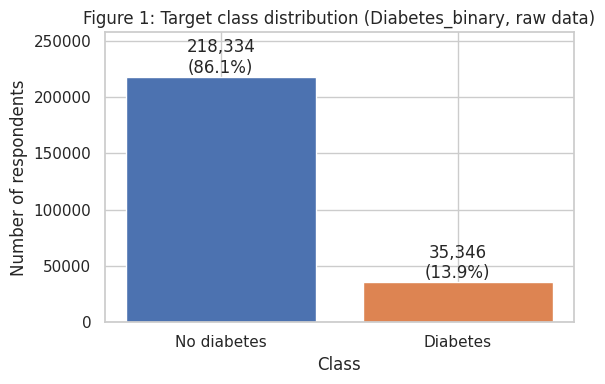

Imbalance ratio (majority : minority) = 6.2 : 1


In [38]:
# ---- Figure 1: target class distribution ----
counts = df_raw[TARGET_COL].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_names, counts.values, color=sns.color_palette("deep", len(counts)))
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set_title(f"Figure 1: Target class distribution ({TARGET_COL}, raw data)")
ax.set_xlabel("Class"); ax.set_ylabel("Number of respondents"); ax.set_ylim(0, counts.max() * 1.18)
save_fig("fig01_class_distribution")
imbalance_ratio = counts.max() / counts.min()
print(f"Imbalance ratio (majority : minority) = {imbalance_ratio:.1f} : 1")

**Interpretation (Figure 1).** Look at the printed percentages and imbalance ratio. In the full binary file, only roughly 14% of respondents report diabetes, so a classifier that *always predicts "no diabetes"* would already reach ~86% accuracy while detecting nobody. **Accuracy is therefore a misleading headline metric here**; we emphasise ROC-AUC, PR-AUC, recall and F1 for the positive class, and we use class weighting and threshold tuning. (The `5050split` file, which was **not** used in this study, is artificially balanced by under-sampling, which changes the prevalence and makes its precision/recall not comparable to the real-world setting.)

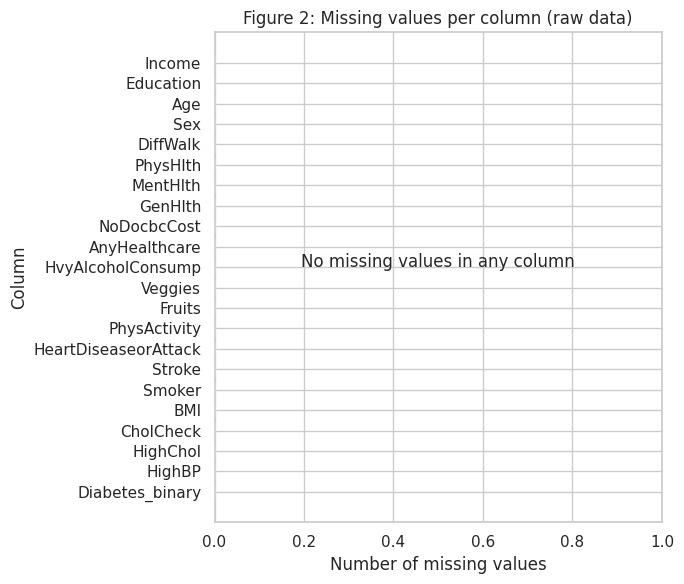

In [39]:
# ---- Figure 2: missing-value summary ----
miss = df_raw.isna().sum().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(miss.index, miss.values, color="tab:red")
ax.set_title("Figure 2: Missing values per column (raw data)")
ax.set_xlabel("Number of missing values"); ax.set_ylabel("Column")
if miss.max() == 0:
    ax.set_xlim(0, 1); ax.text(0.5, len(miss) / 2, "No missing values in any column", ha="center", fontsize=12)
save_fig("fig02_missing_values")

**Interpretation (Figure 2).** The published CDC Diabetes Health Indicators files were already cleaned (respondents with unusable answers were removed), so you should see zero missing values. That does **not** mean the data is free of bias: removing incomplete respondents is itself a selection step (see limitations in Section 17). If your run shows missing values, an imputer must be added inside the pipeline (fit on training data only).

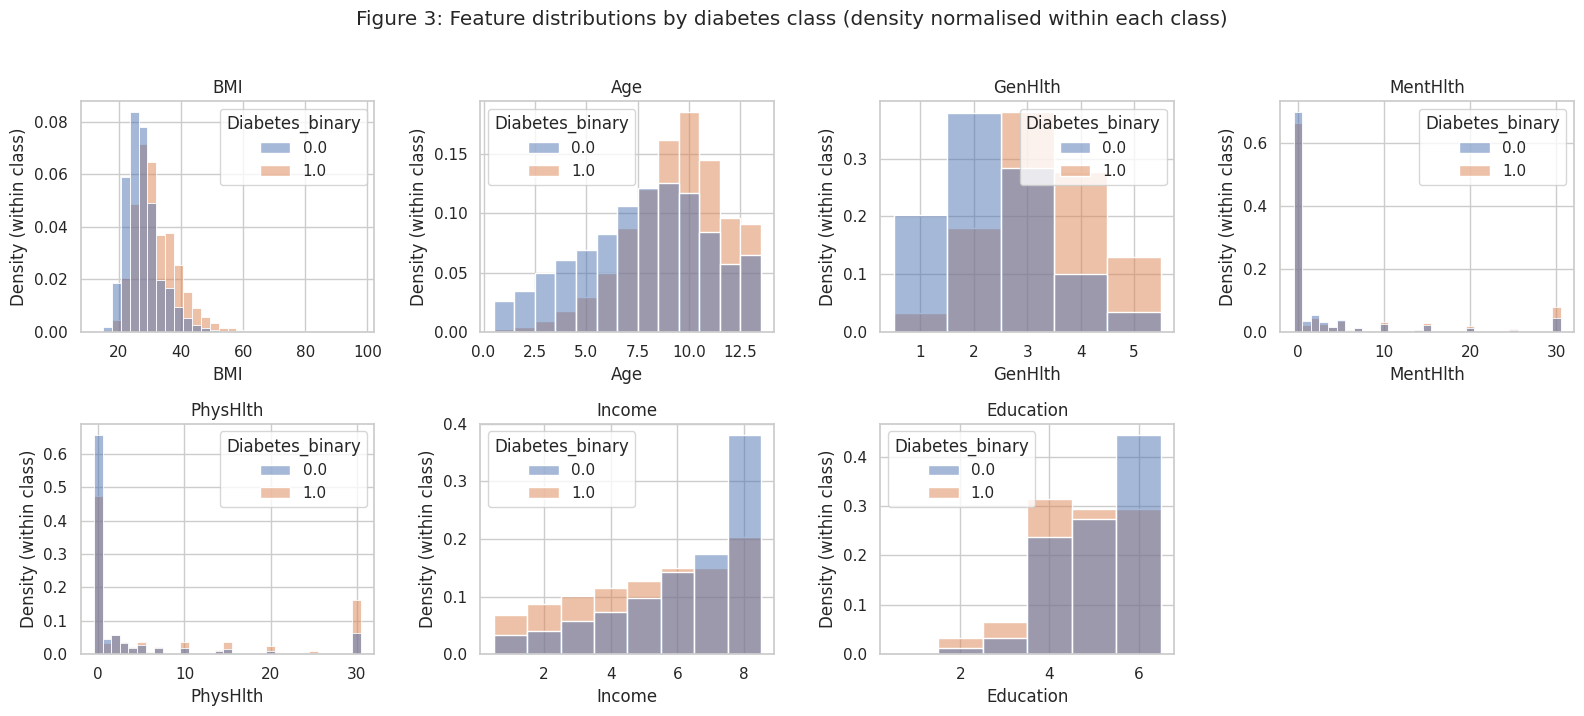

In [40]:
# ---- Figure 3: distributions of key numeric / ordinal features ----
dist_cols = [c for c in ["BMI", "Age", "GenHlth", "MentHlth", "PhysHlth", "Income", "Education"] if c in df_raw.columns]
fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
for ax, c in zip(axes, dist_cols):
    sns.histplot(data=df_raw, x=c, hue=TARGET_COL, bins=30 if c == "BMI" else None, discrete=(c != "BMI"),
                 stat="density", common_norm=False, palette="deep", ax=ax)
    ax.set_title(c); ax.set_xlabel(c); ax.set_ylabel("Density (within class)")
for ax in axes[len(dist_cols):]:
    ax.axis("off")
fig.suptitle("Figure 3: Feature distributions by diabetes class (density normalised within each class)", y=1.02)
save_fig("fig03_feature_distributions")

**Interpretation (Figure 3).** Densities are normalised *within* each class so that the small positive class is visible. Where the curves for the classes separate (typically higher BMI, older age band, worse `GenHlth`, more `PhysHlth` bad days, lower `Income`/`Education` among the diabetes group) the feature carries signal. Heavy overlap means no single feature separates the classes, which is why combining features in a model is needed. `MentHlth`/`PhysHlth` are strongly right-skewed (most respondents report 0 bad days), a hint that scaling and tree-based models may behave differently.

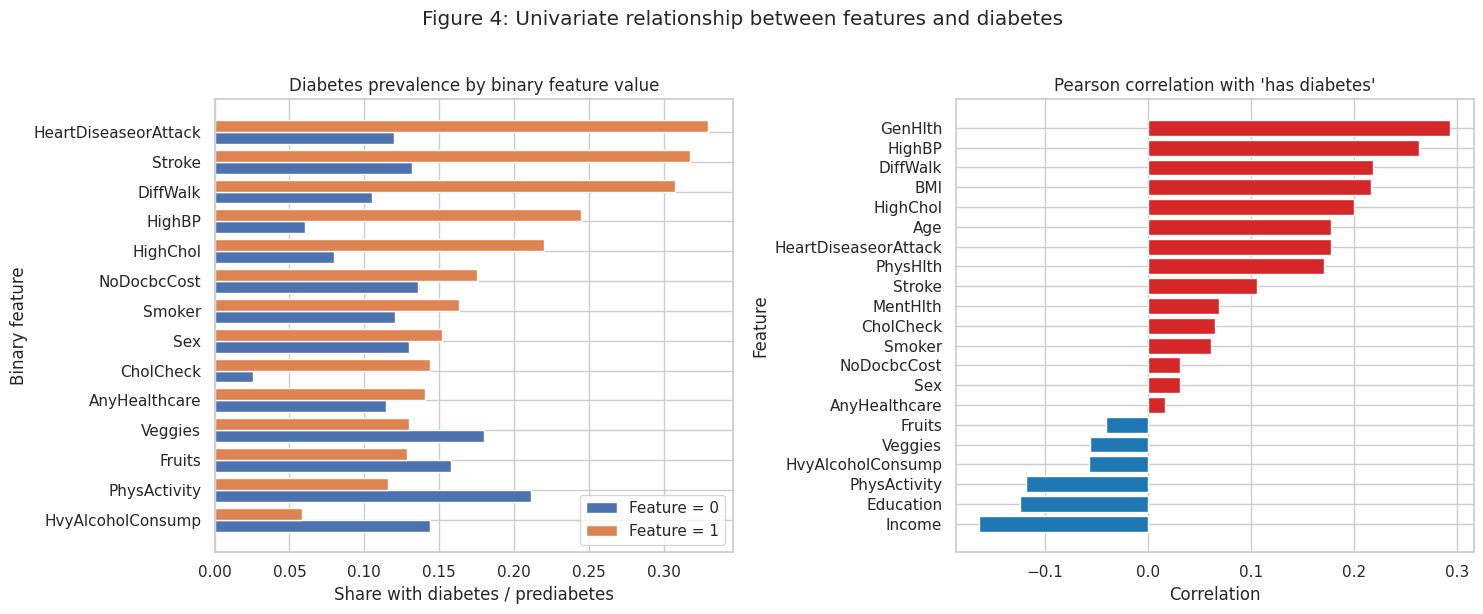

In [41]:
# ---- Figure 4: diabetes prevalence per binary feature + correlation with target ----
tmp = df_raw.copy()
tmp["_pos"] = (tmp[TARGET_COL] > 0).astype(int)          # "any diabetes" indicator for plotting only
bin_cols = [c for c in tmp.columns if c not in (TARGET_COL, "_pos") and tmp[c].nunique() == 2]
prev = pd.DataFrame({c: {"Feature = 0": tmp.loc[tmp[c] == tmp[c].min(), "_pos"].mean(),
                         "Feature = 1": tmp.loc[tmp[c] == tmp[c].max(), "_pos"].mean()} for c in bin_cols}).T
prev = prev.sort_values("Feature = 1")
corr_t = tmp.drop(columns=[TARGET_COL]).corr()["_pos"].drop("_pos").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
y_pos = np.arange(len(prev))
axes[0].barh(y_pos - 0.2, prev["Feature = 0"], height=0.4, label="Feature = 0")
axes[0].barh(y_pos + 0.2, prev["Feature = 1"], height=0.4, label="Feature = 1")
axes[0].set_yticks(y_pos); axes[0].set_yticklabels(prev.index)
axes[0].set_title("Diabetes prevalence by binary feature value"); axes[0].set_xlabel("Share with diabetes / prediabetes"); axes[0].set_ylabel("Binary feature"); axes[0].legend()
axes[1].barh(corr_t.index, corr_t.values, color=np.where(corr_t.values > 0, "tab:red", "tab:blue"))
axes[1].set_title("Pearson correlation with 'has diabetes'"); axes[1].set_xlabel("Correlation"); axes[1].set_ylabel("Feature")
fig.suptitle("Figure 4: Univariate relationship between features and diabetes", y=1.02)
save_fig("fig04_prevalence_correlation")

**Interpretation (Figure 4).** Left: for each 0/1 feature, compare the two bars. A large gap (for example `HighBP`, `HighChol`, `HeartDiseaseorAttack`, `DiffWalk`) means the flag is strongly associated with diabetes. Right: linear correlation with the outcome ranks features (`GenHlth`, `HighBP`, `BMI`, `Age`, `DiffWalk` tend to sit at the top). Remember **association is not causation**, and correlated features (e.g. `HighBP` and `HighChol`) carry overlapping information. Features such as `Fruits`, `Veggies`, `AnyHealthcare` usually show small gaps and are expected to contribute little.

### Outlier investigation (Figure 4b)
Before preprocessing we check whether unusual values exist in the numerical variables, using Tukey fences (1.5 x IQR and the stricter 3 x IQR), BMI bands with their diabetes rate, and a check that every coded variable stays inside its valid range.

In [ ]:
# ---- Figure 4b: outlier investigation (BMI, MentHlth, PhysHlth) ----
def tukey_fences(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for c in ["BMI", "MentHlth", "PhysHlth"]:
    s = df_raw[c]; lo, hi = tukey_fences(s); lo3, hi3 = tukey_fences(s, 3.0)
    beyond = (s < lo) | (s > hi)
    rows.append({"Variable": c, "Min": s.min(), "P1": s.quantile(0.01), "Median": s.median(), "P99": s.quantile(0.99), "Max": s.max(),
                 "1.5xIQR fences": f"[{lo:.1f}, {hi:.1f}]", "n beyond 1.5xIQR": int(beyond.sum()), "% beyond 1.5xIQR": round(100 * beyond.mean(), 2),
                 "n beyond 3xIQR": int(((s < lo3) | (s > hi3)).sum())})
display(pd.DataFrame(rows).set_index("Variable"))

# Extreme BMI: how many respondents, and does the diabetes rate behave plausibly?
edges = [0, 15, 18.5, 25, 30, 35, 40, 50, 60, np.inf]
labels = ["<15", "15-<18.5", "18.5-<25", "25-<30", "30-<35", "35-<40", "40-<50", "50-<60", ">=60"]
band = pd.cut(df_raw["BMI"], bins=edges, labels=labels, right=False)
pos = (df_raw[TARGET_COL] > 0).astype(int)
bmi_bands = pd.DataFrame({"n": band.value_counts().reindex(labels), "diabetes rate": pos.groupby(band, observed=False).mean().reindex(labels)})
bmi_bands["% of respondents"] = 100 * bmi_bands["n"] / len(df_raw)
display(bmi_bands[["n", "% of respondents", "diabetes rate"]].round(3))

# Impossible values? (ordinal / count variables must stay inside their coded ranges)
valid_ranges = {"GenHlth": (1, 5), "Age": (1, 13), "Education": (1, 6), "Income": (1, 8), "MentHlth": (0, 30), "PhysHlth": (0, 30)}
bad = {c: int(((df_raw[c] < lo) | (df_raw[c] > hi)).sum()) for c, (lo, hi) in valid_ranges.items() if c in df_raw.columns}
print("Values outside the coded range:", bad)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, c in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    sns.boxplot(x=df_raw[c], ax=ax, color="#9ecae1", fliersize=2); ax.set_title(c)
fig.suptitle("Figure 4b: Outlier inspection (box = IQR, points = beyond 1.5 x IQR)", y=1.03)
save_fig("fig04b_outliers")


**Interpretation (Figure 4b) and decision.** `BMI` ranges from 12 to 98 (Section 4 table), so a long right tail beyond the 1.5 x IQR fence exists; the band table above shows how few respondents sit at the extremes and what their diabetes rate is. `MentHlth` and `PhysHlth` are bounded to 0-30 days with a large spike at 0, so many respondents with several bad days are flagged by the IQR rule although their answers are perfectly valid. The range check shows no impossible values in the coded variables.

**Decision: no rows are removed.** (1) BMI here is calculated from *self-reported* height and weight, so a very high value can be a reporting error or a genuine case of severe obesity, and individual records cannot be verified. (2) Removing the tails would remove exactly the respondents at highest risk and bias the positive class. (3) Tree-based models are insensitive to extreme values. Logistic Regression, the SVM and the network use `StandardScaler`, which is somewhat sensitive to them, and the engineered features `BMI_sq` and `Age_BMI` amplify them; this is accepted and listed as a limitation. A winsorised-BMI sensitivity run is a possible extension.

## 5. Target selection and preprocessing

Decisions (each chosen to avoid leakage):
- **The target is never a predictor.** We drop the target column from `X`, and also drop any other column whose name contains "diabet" (target-derived), if one existed.
- **Duplicates.** With 21 coarse, mostly binary answers, many *different* people legitimately share identical answers, so some duplicates are genuine. Nevertheless, identical rows that fall on both sides of a split let the model "memorise" test points and inflate scores, so we drop exact duplicates (`DROP_DUPLICATES`, switchable). The effect on prevalence is shown below.
- **No imputation needed** (no missing values), but the pipeline would be the place to add one.
- **Outliers are investigated (Figure 4b, Section 4) but not removed.** `BMI` runs from 12 to 98, but respondents with very high or low BMI can be genuine, and removing them would remove exactly the high-risk cases we want to detect. Extreme values are therefore retained, and their influence on scaled models is discussed in the limitations.
- **Scaling** (`StandardScaler`) is applied only to non-binary columns and **fitted on the training set only**, inside the pipeline / preprocessor, so validation and test statistics never leak.
- **No oversampling** is used. Class imbalance is handled by *class weights* and *threshold tuning* instead; any resampling would have to be done after the split and only on training data.

In [42]:
df = df_raw.copy()
before = len(df)
if DROP_DUPLICATES:
    df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows: {before:,} -> {len(df):,}  (dropped {before - len(df):,} duplicates)")
print("Positive-class share before:", f"{(df_raw[TARGET_COL] > 0).mean():.3%}", "| after:", f"{(df[TARGET_COL] > 0).mean():.3%}")

if SUBSAMPLE_N is not None and len(df) > SUBSAMPLE_N:          # only used for FAST_RUN smoke tests
    df, _ = train_test_split(df, train_size=SUBSAMPLE_N, stratify=df[TARGET_COL], random_state=SEED)
    df = df.reset_index(drop=True)
    print(f"FAST_RUN: stratified subsample of {len(df):,} rows (results are NOT final)")

leak_cols = [c for c in df.columns if "diabet" in c.lower() and c != TARGET_COL]
y = df[TARGET_COL].astype(int)
X = df.drop(columns=[TARGET_COL] + leak_cols)
assert TARGET_COL not in X.columns
print("Feature matrix:", X.shape, "| target classes:", dict(y.value_counts().sort_index()))
print("Features:", list(X.columns))

Rows: 253,680 -> 229,474  (dropped 24,206 duplicates)
Positive-class share before: 13.933% | after: 15.295%
Feature matrix: (229474, 21) | target classes: {0: np.int64(194377), 1: np.int64(35097)}
Features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


### Feature engineering (defined here, evaluated in Section 7)

These features are **row-wise functions** of other columns of the same respondent (no statistics are computed from other rows), so creating them before the split cannot leak information. We test whether they actually help rather than assuming so.

| New feature | Idea |
|---|---|
| `BMI_sq` | Non-linear BMI effect (scaled by 100) |
| `Age_BMI` | Interaction: risk of high BMI grows with age |
| `CardioRiskCount` | Number of cardiovascular risk flags: HighBP, HighChol, Stroke, HeartDiseaseorAttack |
| `HealthyHabits` | PhysActivity + Fruits + Veggies - Smoker - HvyAlcoholConsump |
| `PoorHealthDays` | MentHlth + PhysHlth |
| `Obese` | BMI >= 30 |
| `SES` | Education + Income (socio-economic proxy) |
| `GenHlth_Age` | Interaction of self-rated health and age band |

In [43]:
FE_REQUIRED = {"BMI", "Age", "HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "PhysActivity", "Fruits",
               "Veggies", "Smoker", "HvyAlcoholConsump", "MentHlth", "PhysHlth", "Education", "Income", "GenHlth"}

def add_features(frame):
    """Return a copy of `frame` with engineered features (row-wise only, so no leakage)."""
    f = frame.copy()
    if not FE_REQUIRED.issubset(f.columns):
        print("Engineered features skipped: required columns missing.")
        return f
    f["BMI_sq"] = f["BMI"] ** 2 / 100
    f["Age_BMI"] = f["Age"] * f["BMI"]
    f["CardioRiskCount"] = f[["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack"]].sum(axis=1)
    f["HealthyHabits"] = f["PhysActivity"] + f["Fruits"] + f["Veggies"] - f["Smoker"] - f["HvyAlcoholConsump"]
    f["PoorHealthDays"] = f["MentHlth"] + f["PhysHlth"]
    f["Obese"] = (f["BMI"] >= 30).astype(int)
    f["SES"] = f["Education"] + f["Income"]
    f["GenHlth_Age"] = f["GenHlth"] * f["Age"]
    return f

def make_prep(columns, X_ref):
    """Scale non-binary columns, pass binary columns through. Fitted ONLY when the pipeline is fitted on training data."""
    scale_cols = [c for c in columns if X_ref[c].nunique() > 2]
    return ColumnTransformer([("scale", StandardScaler(), scale_cols)], remainder="passthrough",
                             verbose_feature_names_out=False)

def make_pipe(model, columns, X_ref):
    return Pipeline([("prep", make_prep(columns, X_ref)), ("model", model)])

print(add_features(X.head(3)).iloc[:, -8:])

   BMI_sq  Age_BMI  CardioRiskCount  HealthyHabits  PoorHealthDays  Obese   SES  GenHlth_Age
0   16.00    360.0              2.0            0.0            33.0      1   7.0         45.0
1    6.25    175.0              0.0            0.0             0.0      0   7.0         21.0
2    7.84    252.0              2.0            1.0            60.0      0  12.0         45.0


## 6. Train / validation / test split

A **stratified** 70 / 15 / 15 split keeps the class proportions identical in all three sets.
- **Train (70%)**: fit models and preprocessing, and run cross-validation for tuning.
- **Validation (15%)**: compare models, choose the decision threshold, early stopping and the final models.
- **Test (15%)**: touched **once**, at the end (Section 11), for the final report.

In [44]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
del X_tmp, y_tmp

split_table = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "share": [len(y_train) / len(y), len(y_val) / len(y), len(y_test) / len(y)],
    **{f"{n} %": [(s == c).mean() * 100 for s in (y_train, y_val, y_test)] for c, n in zip(range(N_CLASSES), class_names)}
}, index=["train", "validation", "test"]).round(3)
display(split_table)
assert set(X_train.index).isdisjoint(X_val.index) and set(X_train.index).isdisjoint(X_test.index) and set(X_val.index).isdisjoint(X_test.index)
print("Splits are disjoint. Test set is now locked until Section 11.")

# Engineered versions of each split (row-wise functions, no leakage)
X_train_e, X_val_e, X_test_e = add_features(X_train), add_features(X_val), add_features(X_test)
BASE_COLS, ENG_COLS = list(X_train.columns), list(X_train_e.columns)

,rows,share,No diabetes %,Diabetes %
train,160631,0.70,84.705,15.295
validation,34421,0.15,84.707,15.293
test,34422,0.15,84.705,15.295


Splits are disjoint. Test set is now locked until Section 11.


### Evaluation helpers

All models output a **probability-like score** for each class. For binary problems the positive-class score is thresholded (default 0.5, or a threshold tuned on the **validation** set to maximise positive-class F1). For the SVM (no native probabilities) the decision function is passed through a sigmoid, which does not change ROC-AUC. For multiclass targets, predictions are the arg-max class and ROC-AUC is one-vs-rest macro-averaged.

In [45]:
SCORING = "roc_auc" if N_CLASSES == 2 else "roc_auc_ovr"

def get_scores(model, X_):
    """(n, n_classes) probability-like scores for any fitted sklearn estimator/pipeline."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)
    d = model.decision_function(X_)
    if d.ndim == 1:
        p = 1 / (1 + np.exp(-d))
        return np.column_stack([1 - p, p])
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def roc_auc(y_true, scores):
    return roc_auc_score(y_true, scores[:, 1]) if N_CLASSES == 2 else roc_auc_score(y_true, scores, multi_class="ovr", average="macro")

def best_threshold(y_true, scores):
    """Binary only: threshold in [0.05, 0.95] maximising positive-class F1 (to be called on VALIDATION data)."""
    if N_CLASSES != 2:
        return None
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y_true, (scores[:, 1] >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1s))])

def predict_labels(scores, threshold=0.5):
    return (scores[:, 1] >= threshold).astype(int) if N_CLASSES == 2 else scores.argmax(axis=1)

def evaluate(name, y_true, scores, threshold=0.5):
    y_pred = predict_labels(scores, threshold)
    avg = "binary" if N_CLASSES == 2 else "macro"
    return {"Model": name,
            "Threshold": round(threshold, 2) if N_CLASSES == 2 else np.nan,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, average=avg, zero_division=0),
            "Recall": recall_score(y_true, y_pred, average=avg, zero_division=0),
            "F1": f1_score(y_true, y_pred, average=avg, zero_division=0),
            "Macro-F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "Weighted-F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
            "ROC-AUC": roc_auc(y_true, scores),
            "PR-AUC": average_precision_score(y_true, scores[:, 1]) if N_CLASSES == 2 else np.nan}

POS_LABEL_NOTE = "Precision / Recall / F1 refer to the positive class (diabetes)" if N_CLASSES == 2 else "Precision / Recall / F1 are macro-averaged"
print(POS_LABEL_NOTE)

Precision / Recall / F1 refer to the positive class (diabetes)


## 7. Traditional ML baselines

### 7.1 Feature-engineering experiment
Two fast reference models (Logistic Regression and HistGradientBoosting) are trained on the **base** features and on the **base + engineered** features. The feature set with the higher mean **validation ROC-AUC** is used for every later model. (The test set plays no role.)

In [46]:
fe_rows = []
for set_name, cols in [("base", BASE_COLS), ("base + engineered", ENG_COLS)]:
    for mname, mk in [("Logistic Regression", lambda: LogisticRegression(max_iter=1000, class_weight="balanced")),
                      ("HistGradientBoosting", lambda: HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED))]:
        pipe = make_pipe(mk(), cols, X_train_e)
        t0 = time.time(); pipe.fit(X_train_e[cols], y_train); dt = time.time() - t0
        fe_rows.append({"Feature set": set_name, "n_features": len(cols), "Model": mname,
                        "Val ROC-AUC": roc_auc(y_val, get_scores(pipe, X_val_e[cols])), "Fit time (s)": round(dt, 1)})
fe_table = pd.DataFrame(fe_rows)
display(fe_table.round(4))

mean_auc = fe_table.groupby("Feature set")["Val ROC-AUC"].mean()
FEATURE_SET = mean_auc.idxmax()
FEATURES = ENG_COLS if FEATURE_SET == "base + engineered" else BASE_COLS
print(f"\nMean validation ROC-AUC -> base: {mean_auc.get('base', float('nan')):.4f} | engineered: {mean_auc.get('base + engineered', float('nan')):.4f}")
print(f"Selected feature set: '{FEATURE_SET}' ({len(FEATURES)} features)")

Xtr, Xva, Xte = X_train_e[FEATURES], X_val_e[FEATURES], X_test_e[FEATURES]
fe_table.to_csv(OUT_DIR / "feature_engineering_experiment.csv", index=False)

,Feature set,n_features,Model,Val ROC-AUC,Fit time (s)
0,base,21,Logistic Regression,0.8126,0.7
1,base,21,HistGradientBoosting,0.8193,2.4
2,base + engineered,29,Logistic Regression,0.8160,1.1
3,base + engineered,29,HistGradientBoosting,0.8194,2.5



Mean validation ROC-AUC -> base: 0.8160 | engineered: 0.8177
Selected feature set: 'base + engineered' (29 features)


**Interpretation.** Engineered features raised the mean validation ROC-AUC from 0.8160 (21 base features) to 0.8177 (29 features). The gain comes almost entirely from Logistic Regression (0.8126 -> 0.8160, +0.0034), which cannot build interactions such as `Age x BMI` by itself. HistGradientBoosting is essentially unchanged (0.8193 -> 0.8194) because trees learn interactions on their own. The engineered set is used in all later experiments, but the improvement is small, in line with H4. (The feature set was chosen on validation data, never on the test set.)

### 7.2 Four baseline models
| Model | Notes |
|---|---|
| Logistic Regression | Linear baseline; scaled inputs; `class_weight='balanced'` |
| Random Forest | Bagged trees; `class_weight='balanced_subsample'`; no scaling needed (scaling is harmless) |
| HistGradientBoosting | Histogram-based Gradient Boosting; fast on 200k+ rows |
| SVM (RBF kernel) | Kernel SVM scales roughly quadratically with n, so it is trained on a stratified **subsample** of the training set (`SVM_TRAIN_N`) |

We use class weights because for a **screening** application missing a true case (false negative) is generally worse than a false alarm. The next cell (7.3) tests whether class weighting actually helps.

In [47]:
svm_idx, _ = train_test_split(np.arange(len(Xtr)), train_size=min(SVM_TRAIN_N, len(Xtr)), stratify=y_train, random_state=SEED)

baseline_defs = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced"), None),
    "Random Forest": (RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=SEED), None),
    "HistGradientBoosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED), None),
    "SVM (RBF)": (SVC(kernel="rbf", class_weight="balanced", probability=(N_CLASSES > 2), random_state=SEED), svm_idx),
}
baseline_models, train_time, baseline_val_scores, baseline_rows = {}, {}, {}, []
for name, (est, idx) in baseline_defs.items():
    pipe = make_pipe(est, FEATURES, Xtr)
    Xfit, yfit = (Xtr, y_train) if idx is None else (Xtr.iloc[idx], y_train.iloc[idx])
    t0 = time.time(); pipe.fit(Xfit, yfit); train_time[f"{name} (baseline)"] = time.time() - t0
    baseline_models[name] = pipe
    baseline_val_scores[name] = get_scores(pipe, Xva)
    baseline_rows.append({**evaluate(name, y_val, baseline_val_scores[name]), "Train time (s)": round(train_time[f"{name} (baseline)"], 1)})
baseline_table = pd.DataFrame(baseline_rows).set_index("Model")
print("VALIDATION results (threshold 0.5)  --", POS_LABEL_NOTE)
display(baseline_table.round(4))
baseline_table.to_csv(OUT_DIR / "baseline_validation_results.csv")

VALIDATION results (threshold 0.5)  -- Precision / Recall / F1 refer to the positive class (diabetes)


,Threshold,Accuracy,Precision,Recall,F1,Macro-F1,Weighted-F1,ROC-AUC,PR-AUC,Train time (s)
Model,,,,,,,,,,
Logistic Regression,0.5,0.7152,0.3207,0.7709,0.4529,0.6302,0.7533,0.8160,0.4362,1.1
Random Forest,0.5,0.7946,0.3850,0.5745,0.4610,0.6671,0.8101,0.8076,0.4232,18.0
HistGradientBoosting,0.5,0.7099,0.3192,0.7918,0.4550,0.6287,0.7492,0.8194,0.4457,2.5
SVM (RBF),0.5,0.7123,0.3173,0.7654,0.4486,0.6270,0.7508,0.7980,0.3684,14.1


**Interpretation.** With `class_weight='balanced'` and a 0.5 threshold, expect **high recall but low precision** for the positive class (many false alarms) and a *lower accuracy* than the trivial "always negative" classifier. That trade-off is intentional for screening, and it is why ROC-AUC (threshold-independent) is our main model-selection metric. Note the SVM was trained on a much smaller sample, so its comparison is not like-for-like in training size.

**Results (this run).** At threshold 0.5 Logistic Regression, HistGradientBoosting and the SVM show the expected pattern: recall 0.77-0.79, precision 0.32 and accuracy about 0.71. Random Forest is the exception (recall 0.57, precision 0.39, accuracy 0.79), so it already sits at a different operating point. ROC-AUC (0.798-0.819) is the fair comparison across models.

### 7.3 Class-imbalance experiment: class weights vs none
We re-train Logistic Regression and HistGradientBoosting **without** class weights and compare against the weighted versions on validation data, at the default threshold and with a tuned threshold.

In [48]:
cw_rows = []
for name, mk in [("Logistic Regression", lambda: LogisticRegression(max_iter=1000)),
                 ("HistGradientBoosting", lambda: HistGradientBoostingClassifier(random_state=SEED))]:
    unweighted = make_pipe(mk(), FEATURES, Xtr).fit(Xtr, y_train)
    for tag, s in [("no class weight", get_scores(unweighted, Xva)), ("balanced class weight", baseline_val_scores[name])]:
        thr = best_threshold(y_val, s)
        r05, rt = evaluate(name, y_val, s, 0.5), evaluate(name, y_val, s, thr if thr else 0.5)
        cw_rows.append({"Model": name, "Setting": tag, "ROC-AUC": r05["ROC-AUC"], "Recall @0.5": r05["Recall"],
                        "Precision @0.5": r05["Precision"], "F1 @0.5": r05["F1"], "Best thr": thr, "F1 @best thr": rt["F1"]})
cw_table = pd.DataFrame(cw_rows)
display(cw_table.round(4))
cw_table.to_csv(OUT_DIR / "class_weight_experiment.csv", index=False)

,Model,Setting,ROC-AUC,Recall @0.5,Precision @0.5,F1 @0.5,Best thr,F1 @best thr
0,Logistic Regression,no class weight,0.8157,0.1738,0.5802,0.2675,0.21,0.4707
1,Logistic Regression,balanced class weight,0.8160,0.7709,0.3207,0.4529,0.63,0.4710
2,HistGradientBoosting,no class weight,0.8201,0.1655,0.5937,0.2588,0.24,0.4799
3,HistGradientBoosting,balanced class weight,0.8194,0.7918,0.3192,0.4550,0.63,0.4798


**Interpretation.** Class weighting mostly moves the *operating point* (recall up, precision down at 0.5) but changes ROC-AUC very little, because it does not give the model more information. The more important comparison is the last column: after tuning the threshold on validation data, weighted and unweighted models usually reach a similar best F1. Hence the weights are a convenience; **threshold selection is the real lever** for the screening trade-off.

**Results (this run).** Class weighting leaves ROC-AUC unchanged (Logistic Regression 0.8157 -> 0.8160, HistGradientBoosting 0.8201 -> 0.8194) but moves recall at 0.5 from about 0.17 to about 0.77-0.79 and precision from about 0.58 to about 0.32. When each setting gets its own best threshold, the F1 scores are the same (0.4707 vs 0.4710 and 0.4799 vs 0.4798), so weighting and threshold tuning are largely interchangeable here.

## 8. Traditional ML hyperparameter tuning

**Method:** `RandomizedSearchCV` on the training data only.
- **Cross-validation:** stratified K-fold (`CV_FOLDS`, shuffled, fixed seed) *inside the training set*; the validation and test sets are never used here.
- **Scoring metric:** ROC-AUC (threshold-independent and robust to imbalance).
- **Search budget:** `N_ITER_SEARCH` random candidates per model, on a stratified sample of `TUNE_SAMPLE_N` training rows to keep Colab runtime manageable. The best configuration is then **refit on the full training set**.
- **Search spaces**
  - Logistic Regression: `C` log-uniform in [1e-3, 1e2]
  - Random Forest: `n_estimators` in {100, 200, 300}, `max_depth` in {8, 12, 16, None}, `min_samples_leaf` in {1, 5, 10, 20}, `max_features` in {sqrt, 0.5}
  - HistGradientBoosting: `learning_rate` log-uniform [0.02, 0.3], `max_iter` in {100, 200, 300}, `max_leaf_nodes` in {15, 31, 63}, `min_samples_leaf` in {20, 50, 100}, `l2_regularization` uniform [0, 5]
  - SVM: `C` in {0.5, 1, 2} compared on validation data (too slow for full cross-validation)

In [49]:
tune_idx, _ = train_test_split(np.arange(len(Xtr)), train_size=min(TUNE_SAMPLE_N, len(Xtr)), stratify=y_train, random_state=SEED)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

search_defs = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                            {"model__C": loguniform(1e-3, 1e2)}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
                      {"model__n_estimators": [100, 200, 300], "model__max_depth": [8, 12, 16, None],
                       "model__min_samples_leaf": [1, 5, 10, 20], "model__max_features": ["sqrt", 0.5]}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                             {"model__learning_rate": loguniform(0.02, 0.3), "model__max_iter": [100, 200, 300],
                              "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [20, 50, 100],
                              "model__l2_regularization": uniform(0, 5)}),
}
tuned_models, best_params, cv_tables = {}, {}, {}
for name, (est, space) in search_defs.items():
    print(f"--- Tuning {name} ({N_ITER_SEARCH} candidates x {CV_FOLDS} folds) ---")
    search = RandomizedSearchCV(make_pipe(est, FEATURES, Xtr), space, n_iter=N_ITER_SEARCH, scoring=SCORING,
                                cv=cv, random_state=SEED, n_jobs=1, refit=False, verbose=0)
    t0 = time.time(); search.fit(Xtr.iloc[tune_idx], y_train.iloc[tune_idx]); t_search = time.time() - t0
    best_params[name] = {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}
    print(f"best CV {SCORING}: {search.best_score_:.4f} | params: {best_params[name]} | search time {t_search:.0f}s")
    t0 = time.time()
    final_pipe = clone(search.estimator).set_params(**search.best_params_).fit(Xtr, y_train)   # refit on FULL training set
    train_time[f"{name} (tuned)"] = time.time() - t0 + t_search
    tuned_models[name] = final_pipe
    cv_tables[name] = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")[["rank_test_score", "mean_test_score", "std_test_score", "params"]]
    cv_tables[name].to_csv(OUT_DIR / f"tuning_cv_results_{name.replace(' ', '_')}.csv", index=False)

# SVM: compare C on validation data (trained on the stratified subsample)
svm_rows, svm_fits = [], {}
for C in [0.5, 1.0, 2.0]:
    pipe = make_pipe(SVC(kernel="rbf", C=C, class_weight="balanced", probability=(N_CLASSES > 2), random_state=SEED), FEATURES, Xtr)
    t0 = time.time(); pipe.fit(Xtr.iloc[svm_idx], y_train.iloc[svm_idx]); dt = time.time() - t0
    svm_fits[C] = (pipe, dt); svm_rows.append({"C": C, "Val ROC-AUC": roc_auc(y_val, get_scores(pipe, Xva)), "Fit time (s)": round(dt, 1)})
svm_table = pd.DataFrame(svm_rows); display(svm_table.round(4))
best_C = float(svm_table.loc[svm_table["Val ROC-AUC"].idxmax(), "C"])
tuned_models["SVM (RBF)"] = svm_fits[best_C][0]; best_params["SVM (RBF)"] = {"C": best_C, "kernel": "rbf", "train_subsample": int(len(svm_idx))}
train_time["SVM (RBF) (tuned)"] = sum(dt for _, dt in svm_fits.values())
print("Selected SVM C =", best_C)

--- Tuning Logistic Regression (6 candidates x 3 folds) ---
best CV roc_auc: 0.8129 | params: {'C': 0.0745934328572655} | search time 10s
--- Tuning Random Forest (6 candidates x 3 folds) ---
best CV roc_auc: 0.8113 | params: {'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 12} | search time 117s
--- Tuning HistGradientBoosting (6 candidates x 3 folds) ---
best CV roc_auc: 0.8152 | params: {'l2_regularization': 1.5212112147976886, 'learning_rate': 0.08283072221077194, 'max_iter': 100, 'max_leaf_nodes': 15, 'min_samples_leaf': 100} | search time 19s


,C,Val ROC-AUC,Fit time (s)
0,0.5,0.8026,13.9
1,1.0,0.7980,13.9
2,2.0,0.7923,14.1


Selected SVM C = 0.5


**Interpretation.** For each model the printed line shows the best cross-validated ROC-AUC and parameters. If the best parameters sit at the **edge** of the search space (e.g. the largest `max_iter`, or `max_depth=None` for Random Forest), a wider search could help. Differences between top candidates are often smaller than the cross-validation standard deviation, which you can inspect in the saved `tuning_cv_results_*.csv` files; don't over-interpret small gaps. Tuning was run on a sample of the training data and with a small random budget by design, to keep the runtime manageable.

In [50]:
tuned_val_scores = {n: get_scores(m, Xva) for n, m in tuned_models.items()}
tuned_rows = []
for n, s in tuned_val_scores.items():
    thr = best_threshold(y_val, s)
    tuned_rows.append({**evaluate(n, y_val, s, 0.5 if thr is None else thr), "Train time (s)": round(train_time[f"{n} (tuned)"], 1)})
tuned_table = pd.DataFrame(tuned_rows).set_index("Model")
print("VALIDATION results of tuned traditional models (threshold tuned on validation)")
display(tuned_table.round(4))
tuned_table.to_csv(OUT_DIR / "tuned_traditional_validation_results.csv")

BEST_TRAD = tuned_table["ROC-AUC"].idxmax()
print(f"\nBest traditional model on VALIDATION ROC-AUC: {BEST_TRAD} ({tuned_table.loc[BEST_TRAD, 'ROC-AUC']:.4f})")

VALIDATION results of tuned traditional models (threshold tuned on validation)


,Threshold,Accuracy,Precision,Recall,F1,Macro-F1,Weighted-F1,ROC-AUC,PR-AUC,Train time (s)
Model,,,,,,,,,,
Logistic Regression,0.60,0.7761,0.3689,0.6529,0.4714,0.6647,0.7988,0.8160,0.4361,11.2
Random Forest,0.62,0.7979,0.3945,0.6016,0.4765,0.6756,0.8138,0.8173,0.4397,129.1
HistGradientBoosting,0.64,0.7919,0.3877,0.6227,0.4779,0.6740,0.8101,0.8198,0.4458,21.8
SVM (RBF),0.64,0.7830,0.3737,0.6204,0.4665,0.6651,0.8030,0.8026,0.3754,41.8



Best traditional model on VALIDATION ROC-AUC: HistGradientBoosting (0.8198)


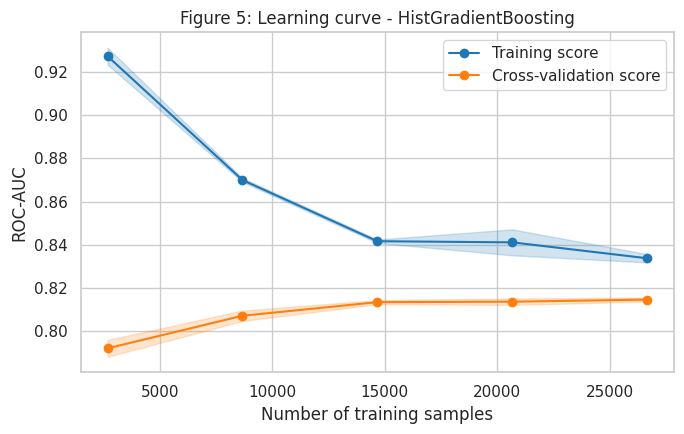

In [51]:
# ---- Figure 5: learning curve of the best traditional model (ROC-AUC vs training-set size) ----
lc_idx, _ = train_test_split(np.arange(len(Xtr)), train_size=min(LC_SAMPLE_N, len(Xtr)), stratify=y_train, random_state=SEED)
sizes, tr_sc, va_sc = learning_curve(clone(tuned_models[BEST_TRAD]), Xtr.iloc[lc_idx], y_train.iloc[lc_idx],
                                     train_sizes=np.linspace(0.1, 1.0, 5), cv=cv, scoring=SCORING, n_jobs=1, random_state=SEED)
fig, ax = plt.subplots(figsize=(7, 4.5))
for sc, lab, col in [(tr_sc, "Training score", "tab:blue"), (va_sc, "Cross-validation score", "tab:orange")]:
    ax.plot(sizes, sc.mean(axis=1), "o-", label=lab, color=col)
    ax.fill_between(sizes, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), alpha=0.2, color=col)
ax.set_title(f"Figure 5: Learning curve - {BEST_TRAD}"); ax.set_xlabel("Number of training samples"); ax.set_ylabel("ROC-AUC"); ax.legend()
save_fig("fig05_learning_curve_traditional")

**Interpretation (Figure 5).** The gap between the training and cross-validation curves shows **variance (overfitting)**; both curves being low and close together shows **bias (underfitting)**. If the CV curve is still rising at the right edge, more data would help; if it has plateaued, gains must come from better features or models. Flexible models (Random Forest, boosting) usually show a visible train/CV gap, while Logistic Regression's curves sit close together at a lower level.

## 9. Deep learning with TensorFlow / Keras and `tf.data`

**Why a feed-forward network for tabular data?** Rows are independent, fixed-length vectors without spatial or sequential structure, so convolutional or recurrent layers have nothing to exploit. A multilayer perceptron (MLP) with ReLU activations can learn non-linear feature interactions. Known challenges: tabular MLPs often only *match* gradient boosting, are sensitive to scaling (we standardise non-binary inputs), and can overfit (so we use dropout, L2 weight decay, batch normalisation and early stopping).

**Design (Keras Functional API)**
`Input -> [Dense -> BatchNorm -> ReLU -> Dropout] x k -> Dense(1, sigmoid)` for binary targets (or `Dense(K, softmax)` for multiclass).
- **Loss:** binary cross-entropy (or sparse categorical cross-entropy for multiclass).
- **Optimiser:** Adam. **Callbacks:** EarlyStopping on the validation metric (restoring best weights) and ReduceLROnPlateau.
- **Imbalance:** per-sample weights from "balanced" class weights, computed from the training labels only.
- **Input pipeline:** `tf.data.Dataset.from_tensor_slices -> shuffle -> batch -> prefetch`. The scaler is fitted on the training set only and applied to validation/test.

We run **four configurations** (different depth/width, dropout, L2, learning rate and batch size) and pick the winner by **validation** ROC-AUC.

In [52]:
# Preprocessing for the network: scaler fitted on TRAIN only
prep_nn = make_prep(FEATURES, Xtr)
Xtr_t = prep_nn.fit_transform(Xtr).astype("float32")
Xva_t = prep_nn.transform(Xva).astype("float32")
Xte_t = prep_nn.transform(Xte).astype("float32")
NN_FEATURE_NAMES = list(prep_nn.get_feature_names_out())
print("Network input shape:", Xtr_t.shape, "| features:", len(NN_FEATURE_NAMES))

cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train.values)
print("Class weights (from training labels):", dict(zip(class_names, cw.round(3))))

def to_labels(y_):
    return y_.values.astype("float32") if N_CLASSES == 2 else y_.values.astype("int32")

def make_ds(X_, y_, batch_size, training=False):
    """tf.data pipeline. Training: (x, y, sample_weight) shuffled each epoch; evaluation: (x, y)."""
    if training:
        w = cw[y_.values].astype("float32")
        ds = tf.data.Dataset.from_tensor_slices((X_, to_labels(y_), w))
        ds = ds.shuffle(buffer_size=min(len(X_), 50_000), seed=SEED, reshuffle_each_iteration=True)
    else:
        ds = tf.data.Dataset.from_tensor_slices((X_, to_labels(y_)))
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def build_model(input_dim, hidden, dropout, lr, l2):
    inputs = keras.Input(shape=(input_dim,), name="features")
    x = inputs
    for i, u in enumerate(hidden):
        x = layers.Dense(u, kernel_regularizer=regularizers.l2(l2), name=f"dense_{i}")(x)
        x = layers.BatchNormalization(name=f"bn_{i}")(x)
        x = layers.Activation("relu", name=f"relu_{i}")(x)
        x = layers.Dropout(dropout, name=f"dropout_{i}")(x)
    if N_CLASSES == 2:
        outputs = layers.Dense(1, activation="sigmoid", name="output")(x)
        loss, metrics = "binary_crossentropy", [keras.metrics.AUC(name="auc"), keras.metrics.Precision(name="precision"),
                                                keras.metrics.Recall(name="recall"), "accuracy"]
    else:
        outputs = layers.Dense(N_CLASSES, activation="softmax", name="output")(x)
        loss, metrics = "sparse_categorical_crossentropy", ["accuracy"]
    model = keras.Model(inputs, outputs, name="diabetes_mlp")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss=loss, metrics=metrics)
    return model

def nn_scores(model, X_, batch=4096):
    p = model.predict(tf.data.Dataset.from_tensor_slices(X_).batch(batch), verbose=0)
    return np.column_stack([1 - p[:, 0], p[:, 0]]) if N_CLASSES == 2 else p

MONITOR, MODE = ("val_auc", "max") if N_CLASSES == 2 else ("val_accuracy", "max")
build_model(Xtr_t.shape[1], [128, 64], 0.3, 1e-3, 1e-5).summary()

Network input shape: (160631, 29) | features: 29
Class weights (from training labels): {'No diabetes': np.float64(0.59), 'Diabetes': np.float64(3.269)}


Model: "diabetes_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_0 (Dense)                 │ (None, 128)            │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_0 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_0 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,545 (49.00 KB)

 Non-trainable params: 384 (1.50 KB)

### 9.0 Experiment tracking (TensorBoard and Weights & Biases, offline)

Every neural-network run is logged twice:
- **TensorBoard** - per-epoch curves in `tracking/tensorboard/<NN-id>/` (view in Colab with `%load_ext tensorboard` then `%tensorboard --logdir <that folder>`).
- **Weights & Biases in offline mode** - needs no account or network. Each run stores the architecture, learning rate, batch size, dropout, L2, epochs run, per-epoch metrics, final **validation ROC-AUC** and **training time** in `tracking/wandb/` (upload later with `wandb sync tracking/wandb/wandb/offline-run-*`).

If W&B cannot be installed the notebook continues with TensorBoard and the CSV tables. The traditional-model experiments (parameters, scores, times) are tracked in the CSV files and in the consolidated table of Section 14.1.

In [ ]:
# ---- Experiment tracking: TensorBoard + Weights & Biases (OFFLINE mode) ----
TRACK_DIR = OUT_DIR / "tracking"
TB_DIR, WANDB_DIR = TRACK_DIR / "tensorboard", TRACK_DIR / "wandb"
TB_DIR.mkdir(parents=True, exist_ok=True); WANDB_DIR.mkdir(parents=True, exist_ok=True)

USE_WANDB = True            # set False to use TensorBoard only
WANDB_OK = False
if USE_WANDB:
    os.environ["WANDB_MODE"] = "offline"      # no account, no network: runs are written to disk and can be synced later
    os.environ["WANDB_SILENT"] = "true"
    try:
        import wandb
        WANDB_OK = True
    except ImportError:
        try:
            import subprocess
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wandb"])
            import wandb
            WANDB_OK = True
        except Exception as e:
            print("wandb could not be installed - continuing with TensorBoard + CSV tracking only.", type(e).__name__)
print("TensorBoard logs :", TB_DIR)
print("W&B offline runs :", WANDB_DIR if WANDB_OK else "disabled")

def start_tracking(cfg, n_params):
    """Open one offline W&B run for a network configuration (returns None when W&B is unavailable)."""
    if not WANDB_OK:
        return None
    try:
        return wandb.init(project="diabetes-classification", name=cfg["name"], dir=str(WANDB_DIR), mode="offline", reinit=True,
                          config={"architecture": "MLP " + "-".join(map(str, cfg["hidden"])), "hidden_units": cfg["hidden"],
                                  "dropout": cfg["dropout"], "learning_rate": cfg["lr"], "l2": cfg["l2"], "batch_size": cfg["batch"],
                                  "max_epochs": NN_MAX_EPOCHS, "early_stopping_patience": NN_PATIENCE, "n_parameters": int(n_params),
                                  "n_input_features": int(Xtr_t.shape[1]), "feature_set": FEATURE_SET, "seed": SEED})
    except Exception as e:
        print("W&B run could not start:", type(e).__name__, e); return None

def finish_tracking(run, history_df, val_roc_auc, train_seconds):
    """Log per-epoch metrics plus the validation ROC-AUC and training time, then close the run."""
    if run is None:
        return
    try:
        for ep, row in history_df.reset_index(drop=True).iterrows():
            run.log({"epoch": ep + 1, **{k: float(v) for k, v in row.items()}})
        run.summary["val_roc_auc"] = float(val_roc_auc)
        run.summary["training_time_s"] = float(train_seconds)
        run.summary["epochs_run"] = int(len(history_df))
        run.finish()
    except Exception as e:
        print("W&B logging failed:", type(e).__name__, e)


### 9.1 Neural-network experiments

In [53]:
NN_CONFIGS = [
    dict(name="NN-A: [128,64] baseline",        hidden=[128, 64],     dropout=0.3, lr=1e-3, l2=1e-5, batch=512),
    dict(name="NN-B: [256,128,64] wider/deeper", hidden=[256, 128, 64], dropout=0.3, lr=1e-3, l2=1e-5, batch=512),
    dict(name="NN-C: [128,64] dropout 0.5, lr 3e-4", hidden=[128, 64],  dropout=0.5, lr=3e-4, l2=1e-4, batch=512),
    dict(name="NN-D: [128,64,32] batch 2048, lr 3e-3", hidden=[128, 64, 32], dropout=0.3, lr=3e-3, l2=1e-5, batch=2048),
]
if FAST_RUN:
    NN_CONFIGS = NN_CONFIGS[:2]

val_ds = make_ds(Xva_t, y_val, 4096, training=False)
nn_models, nn_histories, nn_val_scores, nn_rows = {}, {}, {}, []
for cfg in NN_CONFIGS:
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(Xtr_t.shape[1], cfg["hidden"], cfg["dropout"], cfg["lr"], cfg["l2"])
    run = start_tracking(cfg, model.count_params())          # Weights & Biases (offline), optional
    train_ds = make_ds(Xtr_t, y_train, cfg["batch"], training=True)
    callbacks = [keras.callbacks.EarlyStopping(monitor=MONITOR, mode=MODE, patience=NN_PATIENCE, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor=MONITOR, mode=MODE, factor=0.5, patience=2, min_lr=1e-6),
                 keras.callbacks.TensorBoard(log_dir=str(TB_DIR / cfg["name"].split(":")[0]), histogram_freq=0)]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=NN_MAX_EPOCHS, callbacks=callbacks, shuffle=False, verbose=0)
    dt = time.time() - t0
    s = nn_scores(model, Xva_t); thr = best_threshold(y_val, s)
    r = evaluate(cfg["name"], y_val, s, 0.5 if thr is None else thr)
    nn_models[cfg["name"]], nn_histories[cfg["name"]], nn_val_scores[cfg["name"]] = model, pd.DataFrame(hist.history), s
    train_time[cfg["name"]] = dt
    finish_tracking(run, nn_histories[cfg["name"]], r["ROC-AUC"], dt)
    nn_rows.append({"Model": cfg["name"], "Hidden": cfg["hidden"], "Dropout": cfg["dropout"], "LR": cfg["lr"], "L2": cfg["l2"],
                    "Batch": cfg["batch"], "Epochs run": len(hist.history["loss"]), "Val ROC-AUC": r["ROC-AUC"],
                    "Val F1 (tuned thr)": r["F1"], "Val Recall": r["Recall"], "Val Precision": r["Precision"], "Train time (s)": round(dt, 1)})
    print(f"{cfg['name']:<45} epochs={len(hist.history['loss']):>2}  val ROC-AUC={r['ROC-AUC']:.4f}  time={dt:.0f}s")

nn_table = pd.DataFrame(nn_rows).set_index("Model")
display(nn_table.round(4))
nn_table.to_csv(OUT_DIR / "nn_experiments_validation.csv")
BEST_NN = nn_table["Val ROC-AUC"].idxmax()
print(f"\nBest neural network on VALIDATION ROC-AUC: {BEST_NN}")

NN-A: [128,64] baseline                       epochs=24  val ROC-AUC=0.8203  time=51s
NN-B: [256,128,64] wider/deeper               epochs=34  val ROC-AUC=0.8203  time=119s
NN-C: [128,64] dropout 0.5, lr 3e-4           epochs=34  val ROC-AUC=0.8192  time=71s
NN-D: [128,64,32] batch 2048, lr 3e-3         epochs=19  val ROC-AUC=0.8199  time=32s


,Hidden,Dropout,LR,L2,Batch,Epochs run,Val ROC-AUC,Val F1 (tuned thr),Val Recall,Val Precision,Train time (s)
Model,,,,,,,,,,,
"NN-A: [128,64] baseline","[128, 64]",0.3,0.0010,0.0000,512,24,0.8203,0.4755,0.6432,0.3771,50.8
"NN-B: [256,128,64] wider/deeper","[256, 128, 64]",0.3,0.0010,0.0000,512,34,0.8203,0.4766,0.6037,0.3938,118.6
"NN-C: [128,64] dropout 0.5, lr 3e-4","[128, 64]",0.5,0.0003,0.0001,512,34,0.8192,0.4742,0.6307,0.3799,71.2
"NN-D: [128,64,32] batch 2048, lr 3e-3","[128, 64, 32]",0.3,0.0030,0.0000,2048,19,0.8199,0.4763,0.6210,0.3862,32.1



Best neural network on VALIDATION ROC-AUC: NN-B: [256,128,64] wider/deeper


**Interpretation.** The table compares the four configurations on validation data only. Look at (i) whether depth/width helps or the extra capacity just overfits, (ii) whether a smaller learning rate with stronger dropout/L2 (NN-C) generalises better but needs more epochs, and (iii) whether large batches with a high learning rate (NN-D) train faster but less accurately. Early stopping means "Epochs run" is usually less than the maximum. Differences of a few thousandths in AUC between configurations are likely within noise.

**Results (this run).** All four configurations are within 0.0011 validation ROC-AUC of each other (0.8192-0.8203), i.e. within noise. NN-A and NN-B tie at 0.8203 to four decimals; NN-B was selected on the unrounded value, although NN-A (24 epochs, about 51 s) is more than twice as cheap as NN-B (34 epochs, about 119 s). Extra depth and width therefore bought essentially nothing. The more heavily regularised, low-learning-rate NN-C was slightly worse (0.8192) and the large-batch NN-D trained fastest (about 32 s) at 0.8199.

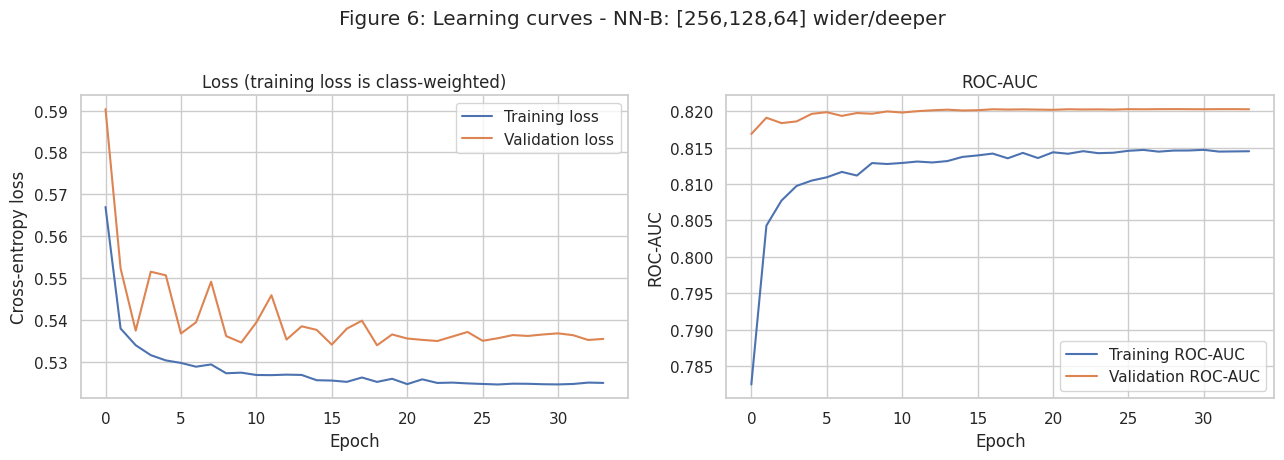

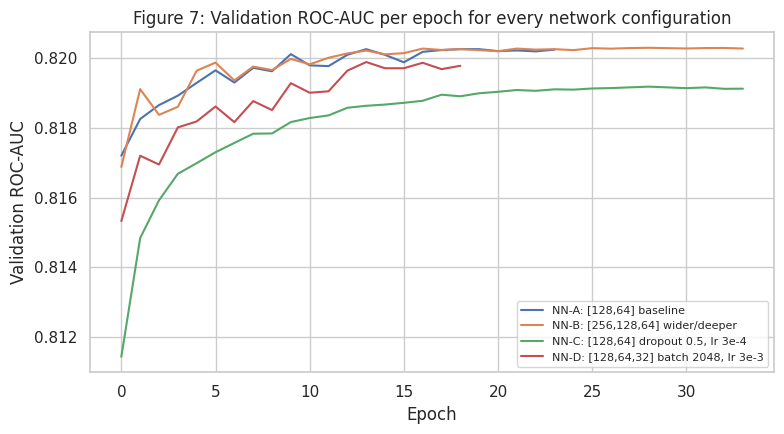

In [54]:
# ---- Figure 6: training / validation learning curves of the selected network ----
h = nn_histories[BEST_NN]
second = ("auc", "ROC-AUC") if N_CLASSES == 2 else ("accuracy", "Accuracy")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(h["loss"], label="Training loss"); axes[0].plot(h["val_loss"], label="Validation loss")
axes[0].set_title("Loss (training loss is class-weighted)"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss"); axes[0].legend()
axes[1].plot(h[second[0]], label=f"Training {second[1]}"); axes[1].plot(h["val_" + second[0]], label=f"Validation {second[1]}")
axes[1].set_title(second[1]); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel(second[1]); axes[1].legend()
fig.suptitle(f"Figure 6: Learning curves - {BEST_NN}", y=1.02)
save_fig("fig06_nn_learning_curves")

# ---- Figure 7: validation metric of all NN experiments ----
fig, ax = plt.subplots(figsize=(8, 4.5))
for n, hh in nn_histories.items():
    ax.plot(hh["val_" + second[0]], label=n)
ax.set_title(f"Figure 7: Validation {second[1]} per epoch for every network configuration")
ax.set_xlabel("Epoch"); ax.set_ylabel(f"Validation {second[1]}"); ax.legend(fontsize=8)
save_fig("fig07_nn_experiments_validation")
for n, hh in nn_histories.items():
    hh.to_csv(OUT_DIR / f"nn_history_{n.split(':')[0].replace(' ', '_')}.csv", index=False)

**Interpretation (Figures 6-7).** In Figure 6, training and validation loss should decrease together at first. If validation loss flattens or rises while training loss keeps falling, the network starts to **overfit**, which is where early stopping restores the best epoch. The training curve may look *worse* than validation in early epochs because dropout is active during training and the training loss is class-weighted. Figure 7 overlays all four experiments: configurations whose curves plateau higher are better; noisy curves suggest a learning rate that is too high.

## 10. Validation-based model selection

The final traditional model and the final neural network were each chosen on **validation ROC-AUC**. We also choose each model's decision threshold on the validation set. Nothing from the test set is used yet.

In [55]:
FINAL_NN_NAME = f"Neural Network ({BEST_NN.split(':')[0]})"
final_names = ["Logistic Regression", "Random Forest", "HistGradientBoosting", "SVM (RBF)", FINAL_NN_NAME]
val_scores_final = {**tuned_val_scores, FINAL_NN_NAME: nn_val_scores[BEST_NN]}
thresholds = {n: (best_threshold(y_val, s) if N_CLASSES == 2 else None) for n, s in val_scores_final.items()}
val_final = pd.DataFrame([evaluate(n, y_val, val_scores_final[n], thresholds[n] or 0.5) for n in final_names]).set_index("Model")
display(val_final.round(4))
val_final.to_csv(OUT_DIR / "final_candidates_validation_results.csv")

BEST_OVERALL = val_final["ROC-AUC"].idxmax()
print(f"Selection metric: validation ROC-AUC")
print(f"Best traditional model : {BEST_TRAD} (val ROC-AUC {tuned_table.loc[BEST_TRAD, 'ROC-AUC']:.4f})")
print(f"Best neural network    : {BEST_NN} (val ROC-AUC {val_final.loc[FINAL_NN_NAME, 'ROC-AUC']:.4f})")
print(f"Best overall on validation: {BEST_OVERALL} (val ROC-AUC {val_final.loc[BEST_OVERALL, 'ROC-AUC']:.4f})")

,Threshold,Accuracy,Precision,Recall,F1,Macro-F1,Weighted-F1,ROC-AUC,PR-AUC
Model,,,,,,,,,
Logistic Regression,0.60,0.7761,0.3689,0.6529,0.4714,0.6647,0.7988,0.8160,0.4361
Random Forest,0.62,0.7979,0.3945,0.6016,0.4765,0.6756,0.8138,0.8173,0.4397
HistGradientBoosting,0.64,0.7919,0.3877,0.6227,0.4779,0.6740,0.8101,0.8198,0.4458
SVM (RBF),0.64,0.7830,0.3737,0.6204,0.4665,0.6651,0.8030,0.8026,0.3754
Neural Network (NN-B),0.66,0.7972,0.3938,0.6037,0.4766,0.6755,0.8135,0.8203,0.4453


Selection metric: validation ROC-AUC
Best traditional model : HistGradientBoosting (val ROC-AUC 0.8198)
Best neural network    : NN-B: [256,128,64] wider/deeper (val ROC-AUC 0.8203)
Best overall on validation: Neural Network (NN-B) (val ROC-AUC 0.8203)


**Why ROC-AUC for selection?** It is threshold-independent, so it compares the *ranking quality* of models without being distorted by class imbalance or by the arbitrary 0.5 cutoff. The decision threshold is then tuned separately (maximising validation F1 for the positive class). For a real screening programme you would instead choose the threshold for a target recall, e.g. "catch at least 80% of cases", and weigh the cost of the extra false alarms.

## 11. Final test-set evaluation (run once)

Every final candidate is evaluated on the **same held-out test set**, with the threshold fixed from validation. We report results at both the default threshold (0.5) and the validation-tuned threshold.

In [56]:
test_scores = {n: get_scores(tuned_models[n], Xte) for n in final_names[:-1]}
test_scores[FINAL_NN_NAME] = nn_scores(nn_models[BEST_NN], Xte_t)

def timing(n):
    return train_time.get(f"{n} (tuned)", train_time.get(BEST_NN)) if n != FINAL_NN_NAME else train_time[BEST_NN]

test_tuned = pd.DataFrame([{**evaluate(n, y_test, test_scores[n], thresholds[n] or 0.5), "Train time (s)": round(timing(n), 1)} for n in final_names]).set_index("Model")
test_default = pd.DataFrame([evaluate(n, y_test, test_scores[n], 0.5) for n in final_names]).set_index("Model")
print("TEST results - threshold tuned on validation  --", POS_LABEL_NOTE)
display(test_tuned.round(4))
print("TEST results - default threshold 0.5")
display(test_default.round(4))
test_tuned.to_csv(OUT_DIR / "test_results_tuned_threshold.csv"); test_default.to_csv(OUT_DIR / "test_results_default_threshold.csv")

for n in final_names:
    print("\n" + "=" * 70 + f"\n{n}  (threshold = {thresholds[n] or 'argmax'})\n" + "=" * 70)
    print(classification_report(y_test, predict_labels(test_scores[n], thresholds[n] or 0.5), target_names=class_names, digits=3, zero_division=0))

TEST results - threshold tuned on validation  -- Precision / Recall / F1 refer to the positive class (diabetes)


,Threshold,Accuracy,Precision,Recall,F1,Macro-F1,Weighted-F1,ROC-AUC,PR-AUC,Train time (s)
Model,,,,,,,,,,
Logistic Regression,0.60,0.7725,0.3619,0.6386,0.4619,0.6588,0.7955,0.8119,0.4273,11.2
Random Forest,0.62,0.7945,0.3871,0.5896,0.4674,0.6700,0.8107,0.8141,0.4331,129.1
HistGradientBoosting,0.64,0.7897,0.3831,0.6141,0.4718,0.6703,0.8080,0.8166,0.4367,21.8
SVM (RBF),0.64,0.7835,0.3746,0.6205,0.4671,0.6656,0.8034,0.8030,0.3766,41.8
Neural Network (NN-B),0.66,0.7964,0.3916,0.5987,0.4735,0.6736,0.8125,0.8182,0.4399,118.6


TEST results - default threshold 0.5


,Threshold,Accuracy,Precision,Recall,F1,Macro-F1,Weighted-F1,ROC-AUC,PR-AUC
Model,,,,,,,,,
Logistic Regression,0.5,0.7147,0.3196,0.7668,0.4512,0.6292,0.7528,0.8119,0.4273
Random Forest,0.5,0.7251,0.3267,0.7514,0.4554,0.6358,0.7610,0.8141,0.4331
HistGradientBoosting,0.5,0.7060,0.3156,0.7890,0.4509,0.6251,0.7460,0.8166,0.4367
SVM (RBF),0.5,0.7043,0.3130,0.7808,0.4468,0.6225,0.7445,0.8030,0.3766
Neural Network (NN-B),0.5,0.6952,0.3104,0.8123,0.4491,0.6192,0.7373,0.8182,0.4399



Logistic Regression  (threshold = 0.6)
              precision    recall  f1-score   support

 No diabetes      0.924     0.797     0.856     29157
    Diabetes      0.362     0.639     0.462      5265

    accuracy                          0.772     34422
   macro avg      0.643     0.718     0.659     34422
weighted avg      0.838     0.772     0.796     34422


Random Forest  (threshold = 0.62)
              precision    recall  f1-score   support

 No diabetes      0.918     0.831     0.873     29157
    Diabetes      0.387     0.590     0.467      5265

    accuracy                          0.794     34422
   macro avg      0.653     0.711     0.670     34422
weighted avg      0.837     0.794     0.811     34422


HistGradientBoosting  (threshold = 0.6399999999999999)
              precision    recall  f1-score   support

 No diabetes      0.922     0.821     0.869     29157
    Diabetes      0.383     0.614     0.472      5265

    accuracy                          0.790     344

**Interpretation.** Compare each model's test numbers with its validation numbers from Section 10: a large drop would indicate overfitting to the validation set (through tuning and threshold selection). In the classification reports, the **recall of the diabetes class** is the proportion of actual cases found; its **precision** is the proportion of flagged people who really have diabetes. *Macro-F1* averages the F1 of both classes equally, whereas *weighted-F1* is dominated by the majority class, so weighted-F1 and accuracy look flattering on imbalanced data.

## 12. Confusion matrices, ROC curves and learning curves

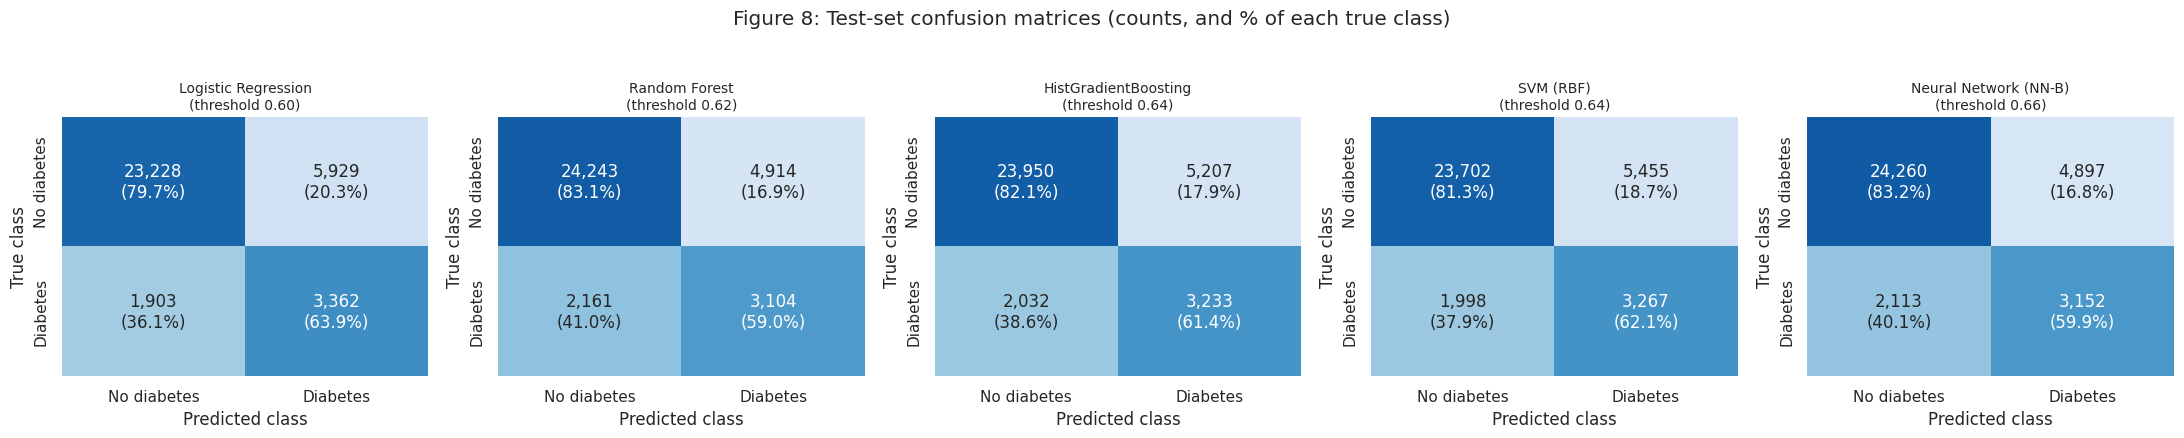

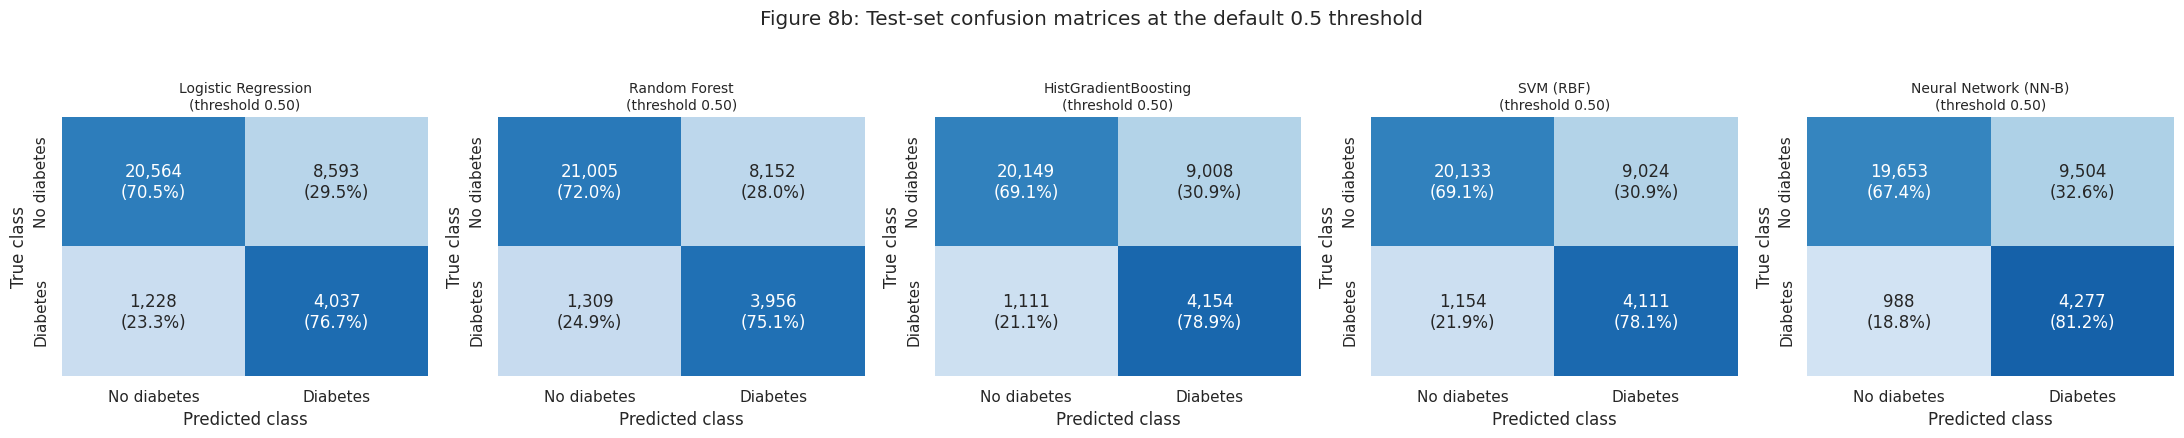

In [57]:
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.1f}%)" for j in range(N_CLASSES)] for i in range(N_CLASSES)])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", cbar=False, vmin=0, vmax=100, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(title, fontsize=10); ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")

# ---- Figure 8: confusion matrices (tuned threshold) ----
fig, axes = plt.subplots(1, len(final_names), figsize=(4.4 * len(final_names), 4.2))
for ax, n in zip(axes, final_names):
    thr = thresholds[n]
    plot_cm(ax, y_test, predict_labels(test_scores[n], thr or 0.5), f"{n}" + (f"\n(threshold {thr:.2f})" if thr else ""))
fig.suptitle("Figure 8: Test-set confusion matrices (counts, and % of each true class)", y=1.04)
save_fig("fig08_confusion_matrices")

# ---- Figure 8b: confusion matrices at default 0.5 threshold ----
if N_CLASSES == 2:
    fig, axes = plt.subplots(1, len(final_names), figsize=(4.4 * len(final_names), 4.2))
    for ax, n in zip(axes, final_names):
        plot_cm(ax, y_test, predict_labels(test_scores[n], 0.5), f"{n}\n(threshold 0.50)")
    fig.suptitle("Figure 8b: Test-set confusion matrices at the default 0.5 threshold", y=1.04)
    save_fig("fig08b_confusion_matrices_default_threshold")

**Interpretation (Figure 8).** Each row is a *true* class and shows what share of it was classified correctly (diagonal) or not. For binary screening, the **bottom-left cell (diabetes predicted as "no diabetes") is the false-negative rate**, i.e. missed cases, and the **top-right cell is the false-positive rate**, i.e. healthy people flagged. Comparing Figure 8 with 8b shows how moving the threshold trades one error for the other.

**Clinical context.** In diabetes *screening*, a false negative means a person with undiagnosed diabetes is reassured and may go untreated; a false positive leads to an unnecessary follow-up test (e.g. an HbA1c blood test), which is usually cheaper and less harmful. That asymmetry usually argues for favouring recall, but with ~14% prevalence, even a decent model produces many more false alarms than true positives, so the cost of follow-up testing matters. This model uses self-reported survey data and is **not** a diagnostic tool.

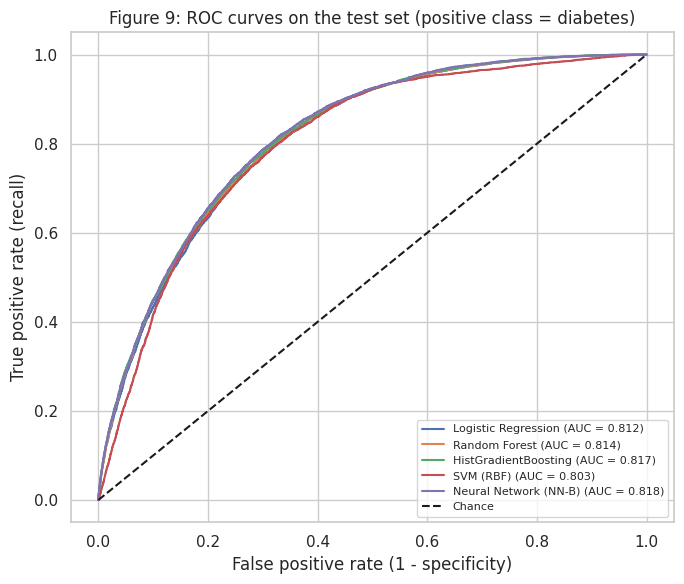

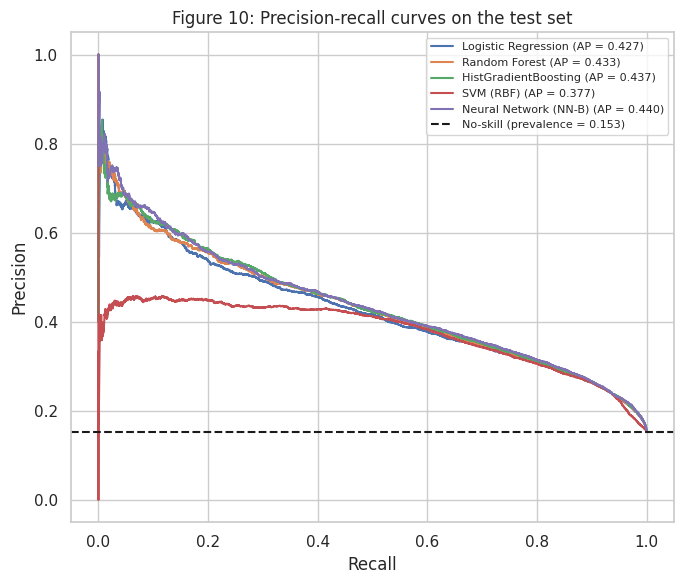

In [58]:
# ---- Figure 9: ROC curves ----
fig, ax = plt.subplots(figsize=(7, 6))
if N_CLASSES == 2:
    for n in final_names:
        fpr, tpr, _ = roc_curve(y_test, test_scores[n][:, 1])
        ax.plot(fpr, tpr, label=f"{n} (AUC = {roc_auc(y_test, test_scores[n]):.3f})")
    ax.set_title("Figure 9: ROC curves on the test set (positive class = diabetes)")
else:
    best_scores = test_scores[BEST_OVERALL]; yb = label_binarize(y_test, classes=range(N_CLASSES))
    for k, cn in enumerate(class_names):
        fpr, tpr, _ = roc_curve(yb[:, k], best_scores[:, k])
        ax.plot(fpr, tpr, label=f"{cn} vs rest (AUC = {roc_auc_score(yb[:, k], best_scores[:, k]):.3f})")
    ax.set_title(f"Figure 9: One-vs-rest ROC curves, {BEST_OVERALL} (macro-AUC = {roc_auc(y_test, best_scores):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Chance"); ax.set_xlabel("False positive rate (1 - specificity)"); ax.set_ylabel("True positive rate (recall)"); ax.legend(loc="lower right", fontsize=8)
save_fig("fig09_roc_curves")

# ---- Figure 10: precision-recall curves (binary) ----
if N_CLASSES == 2:
    fig, ax = plt.subplots(figsize=(7, 6))
    for n in final_names:
        pr, rc, _ = precision_recall_curve(y_test, test_scores[n][:, 1])
        ax.plot(rc, pr, label=f"{n} (AP = {average_precision_score(y_test, test_scores[n][:, 1]):.3f})")
    ax.axhline(y_test.mean(), color="k", ls="--", label=f"No-skill (prevalence = {y_test.mean():.3f})")
    ax.set_title("Figure 10: Precision-recall curves on the test set"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(fontsize=8)
    save_fig("fig10_precision_recall_curves")

**Interpretation (Figures 9-10).** The ROC curve plots the true-positive rate against the false-positive rate over **all** thresholds; the area under it (ROC-AUC) is the probability that a randomly chosen diabetic is ranked above a randomly chosen non-diabetic. Curves that hug the top-left corner are better, and the diagonal is random guessing. When curves for several models nearly overlap, their AUCs differ only marginally. ROC curves can look optimistic under strong imbalance, so the **precision-recall curve** is added: its baseline is the prevalence (a horizontal line), and the distance above it shows real screening value. Choose an operating point by reading off the precision you can get at a required recall.

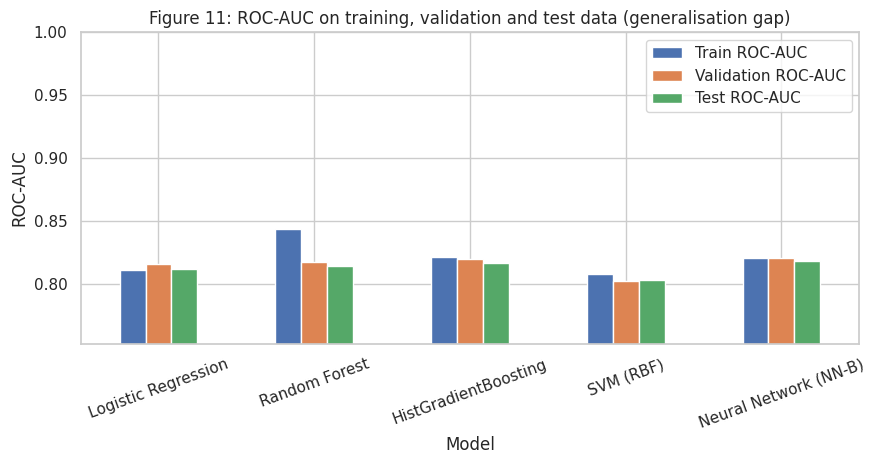

In [59]:
# ---- Figure 11: learning curves of the final network on both metrics already shown in Fig. 6; here: traditional models' train vs val gap ----
gap_rows = []
for n in final_names:
    tr_scores = get_scores(tuned_models[n], Xtr.iloc[:min(len(Xtr), 30000)]) if n in tuned_models else nn_scores(nn_models[BEST_NN], Xtr_t[:30000])
    ytr_ = y_train.iloc[:len(tr_scores)]
    gap_rows.append({"Model": n, "Train ROC-AUC": roc_auc(ytr_, tr_scores), "Validation ROC-AUC": val_final.loc[n, "ROC-AUC"], "Test ROC-AUC": test_tuned.loc[n, "ROC-AUC"]})
gap = pd.DataFrame(gap_rows).set_index("Model")
ax = gap.plot(kind="bar", figsize=(9, 4.8), rot=20)
ax.set_title("Figure 11: ROC-AUC on training, validation and test data (generalisation gap)")
ax.set_xlabel("Model"); ax.set_ylabel("ROC-AUC"); ax.set_ylim(max(0.5, gap.min().min() - 0.05), 1.0)
save_fig("fig11_generalisation_gap")
gap.to_csv(OUT_DIR / "generalisation_gap.csv")

**Interpretation (Figure 11).** This complements the learning curves (Figures 5-6). A **large train-minus-validation gap** (typical for Random Forest, which can nearly memorise its training data) signals overfitting; similar bars across the three data sets signal good generalisation. Validation and test bars should be close because both are unseen; a noticeably lower test bar would suggest the validation set was over-tuned. (Training AUC is computed on the first 30,000 training rows to save time.)

## 13. Feature importance and interpretation

Two complementary views:
- **Impurity-based importance** from the tuned Random Forest (fast, but biased toward high-cardinality / continuous features).
- **Permutation importance** on the validation set for the best traditional model: how much ROC-AUC drops when one feature is shuffled. Computed on a sample of validation rows for speed.

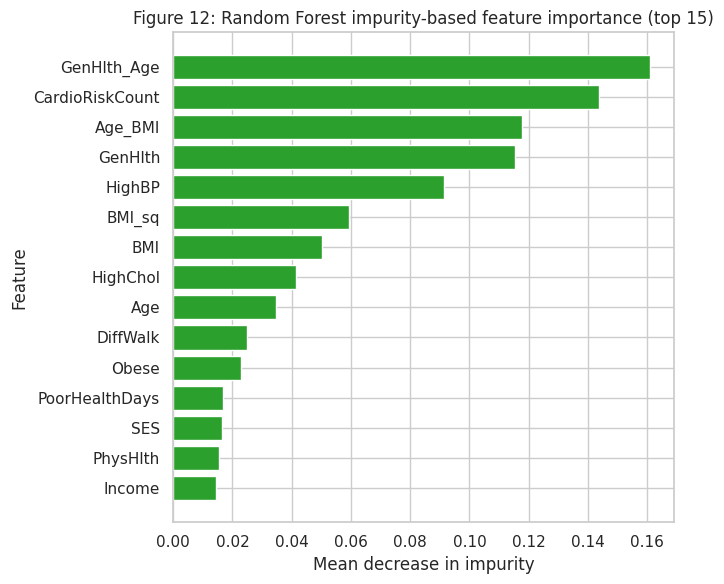

In [60]:
rf_pipe = tuned_models["Random Forest"]
rf_names = rf_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=rf_names).sort_values()
top = imp.tail(15)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color="tab:green")
ax.set_title("Figure 12: Random Forest impurity-based feature importance (top 15)")
ax.set_xlabel("Mean decrease in impurity"); ax.set_ylabel("Feature")
save_fig("fig12_rf_feature_importance")
imp.sort_values(ascending=False).to_csv(OUT_DIR / "rf_feature_importance.csv", header=["importance"])

**Interpretation (Figure 12).** Features at the top are used most often for high-gain splits. Typically `BMI`, `Age`, `GenHlth`, `Income`, `HighBP`, and engineered terms built from them rank high; binary lifestyle flags rank low. Because the engineered features are combinations of base features, importance can be *shared* among them, so a low score for `BMI` does not mean BMI is irrelevant if `BMI_sq`/`Age_BMI` carry the same information. Impurity importance also tends to favour continuous features with many split points.

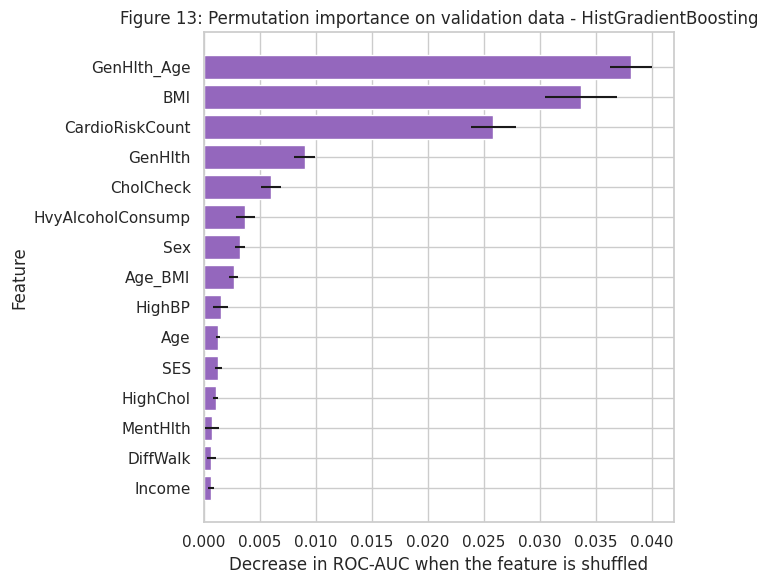

In [61]:
perm_idx, _ = train_test_split(np.arange(len(Xva)), train_size=min(PERM_SAMPLE_N, len(Xva)), stratify=y_val, random_state=SEED)
perm = permutation_importance(tuned_models[BEST_TRAD], Xva.iloc[perm_idx], y_val.iloc[perm_idx], scoring=SCORING,
                              n_repeats=PERM_REPEATS, random_state=SEED, n_jobs=1)
perm_df = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=Xva.columns).sort_values("mean")
top = perm_df.tail(15)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top["mean"], xerr=top["std"], color="tab:purple")
ax.set_title(f"Figure 13: Permutation importance on validation data - {BEST_TRAD}")
ax.set_xlabel("Decrease in ROC-AUC when the feature is shuffled"); ax.set_ylabel("Feature")
save_fig("fig13_permutation_importance")
perm_df.sort_values("mean", ascending=False).to_csv(OUT_DIR / "permutation_importance.csv")

**Interpretation (Figure 13).** Permutation importance measures the *effect on model performance*, so it is more directly tied to prediction quality than impurity importance. Bars near zero (or slightly negative) mean the model does not use or need that feature. Error bars show variability across repeats. Correlated features (e.g. `Age`, `Age_BMI`, `GenHlth_Age`) can **share and hide** each other's importance, because shuffling one leaves the others intact. Compare this ranking with Figure 12 and with the univariate view in Figure 4, and note any disagreements in your report. Importance indicates predictive usefulness, **not causation**.

## 14. Model comparison and findings

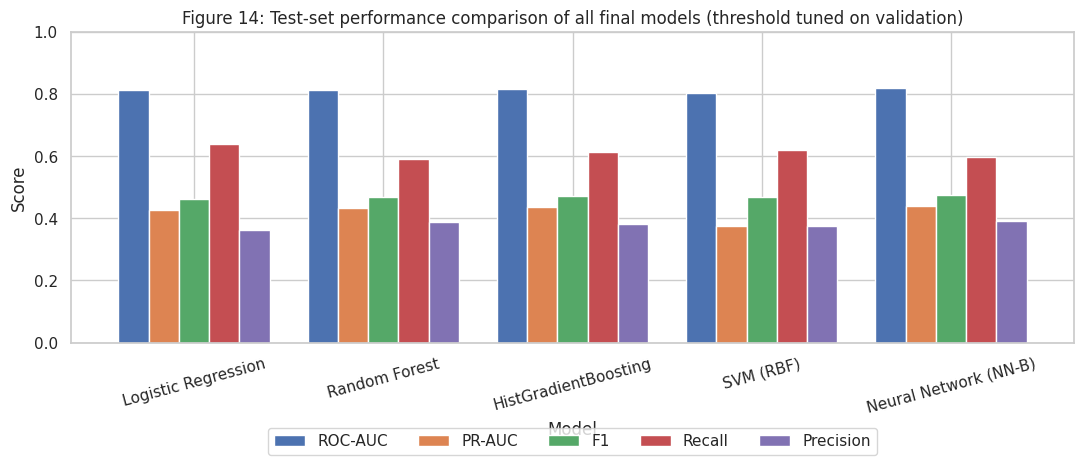

,Val ROC-AUC,Val F1,Test ROC-AUC,Test F1,Test Recall,Test Precision,Test Accuracy,Train time (s)
Model,,,,,,,,
Logistic Regression,0.8160,0.4714,0.8119,0.4619,0.6386,0.3619,0.7725,11.2
Random Forest,0.8173,0.4765,0.8141,0.4674,0.5896,0.3871,0.7945,129.1
HistGradientBoosting,0.8198,0.4779,0.8166,0.4718,0.6141,0.3831,0.7897,21.8
SVM (RBF),0.8026,0.4665,0.8030,0.4671,0.6205,0.3746,0.7835,41.8
Neural Network (NN-B),0.8203,0.4766,0.8182,0.4735,0.5987,0.3916,0.7964,118.6


Selected on validation : Neural Network (NN-B)  (val ROC-AUC 0.8203, test ROC-AUC 0.8182)
Highest test ROC-AUC    : Neural Network (NN-B)  (0.8182)  [reported for information, NOT used for selection]
Best traditional (test) : HistGradientBoosting (0.8166) vs neural network (0.8182)
Logistic Regression baseline test ROC-AUC: 0.8119


In [62]:
metrics_plot = ["ROC-AUC", "PR-AUC", "F1", "Recall", "Precision"] if N_CLASSES == 2 else ["ROC-AUC", "Macro-F1", "Weighted-F1", "Accuracy"]
comp = test_tuned[metrics_plot]
ax = comp.plot(kind="bar", figsize=(11, 5), rot=15, width=0.8)
ax.set_title("Figure 14: Test-set performance comparison of all final models (threshold tuned on validation)")
ax.set_xlabel("Model"); ax.set_ylabel("Score"); ax.set_ylim(0, 1.0); ax.legend(loc="upper center", ncol=len(metrics_plot), bbox_to_anchor=(0.5, -0.25))
save_fig("fig14_model_comparison")

summary = pd.concat([val_final[["ROC-AUC", "F1"]].add_prefix("Val "), test_tuned[["ROC-AUC", "F1", "Recall", "Precision", "Accuracy", "Train time (s)"]].add_prefix("Test ").rename(columns={"Test Train time (s)": "Train time (s)"})], axis=1)
display(summary.round(4)); summary.to_csv(OUT_DIR / "model_comparison_summary.csv")

best_test = test_tuned["ROC-AUC"].idxmax()
trad_best_test = test_tuned.loc[["Logistic Regression", "Random Forest", "HistGradientBoosting", "SVM (RBF)"], "ROC-AUC"]
print(f"Selected on validation : {BEST_OVERALL}  (val ROC-AUC {val_final.loc[BEST_OVERALL, 'ROC-AUC']:.4f}, test ROC-AUC {test_tuned.loc[BEST_OVERALL, 'ROC-AUC']:.4f})")
print(f"Highest test ROC-AUC    : {best_test}  ({test_tuned.loc[best_test, 'ROC-AUC']:.4f})  [reported for information, NOT used for selection]")
print(f"Best traditional (test) : {trad_best_test.idxmax()} ({trad_best_test.max():.4f}) vs neural network ({test_tuned.loc[FINAL_NN_NAME, 'ROC-AUC']:.4f})")
print(f"Logistic Regression baseline test ROC-AUC: {test_tuned.loc['Logistic Regression', 'ROC-AUC']:.4f}")

**Findings (Figure 14 and the summary table).** All numbers are held-out test results unless stated; model selection used validation ROC-AUC only.

- **H1 - supported, but the margin is small.** Tuned HistGradientBoosting (0.8166) and Random Forest (0.8141) beat the Logistic Regression baseline (0.8119) by about 0.005 and 0.002 test ROC-AUC. The notebook does not test the statistical significance of such small gaps.
- **H2 - supported.** The selected network (NN-B, 0.8182) is ahead of HistGradientBoosting by only 0.0016 while taking about five times longer to train (about 119 s vs 22 s in this run). It is comparable to, not clearly better than, gradient boosting.
- **H3 - not supported as written.** The models already use class weights, so the default 0.5 threshold gives *high* recall (NN-B 0.812), not low recall. The validation-tuned (F1-maximising) threshold of 0.66 *lowers* recall to 0.599 while raising precision from 0.310 to 0.392 and F1 from 0.449 to 0.474. Threshold tuning therefore improves the precision/recall balance, not screening recall; a screening tool would need a threshold chosen for a target recall.
- **H4 - supported.** Engineered features raised the mean validation ROC-AUC only from 0.8160 to 0.8177 (Section 7.1), mainly for Logistic Regression.

**Cost versus accuracy.** The RBF-SVM saw only a 20,000-row training subsample, so it is not a like-for-like comparison. Logistic Regression is about ten times cheaper to train than the best models and about 0.006 test ROC-AUC lower. Selection was made on validation data, so the test numbers above are the unbiased estimate to report.

### 14.1 Consolidated experiment table
All experiments in one table: feature engineering, baselines, class weighting, traditional-model tuning (including the SVM `C` sweep), the four neural-network configurations and the final test evaluation. The individual tables in Sections 7-11 are kept. *Dataset* says which split each row was measured on. *Threshold* is blank where only ROC-AUC was recorded (feature engineering and the SVM `C` sweep). Metrics are for the positive (diabetes) class. Saved as `all_experiments.csv`.

In [ ]:
# ---- Table 14.1: every experiment in ONE table ----
exp_rows = []
def add_exp(model, experiment, params, dataset, auc=np.nan, f1=np.nan, recall=np.nan, precision=np.nan, thr=np.nan, t=np.nan, obs=""):
    exp_rows.append({"Experiment ID": f"EXP-{len(exp_rows) + 1:02d}", "Model": model, "Experiment": experiment, "Parameters": params,
                     "Dataset": dataset, "Threshold": thr, "ROC-AUC": auc, "F1": f1, "Recall": recall, "Precision": precision,
                     "Train time (s)": t, "Observation": obs})
TV = "Train / validation"

# (a) feature engineering (Section 7.1) - only ROC-AUC was recorded in this experiment
base_auc = fe_table[fe_table["Feature set"] == "base"].set_index("Model")["Val ROC-AUC"]
for _, r in fe_table.iterrows():
    obs = "Reference (base features)" if r["Feature set"] == "base" else f"Engineered features: {r['Val ROC-AUC'] - base_auc[r['Model']]:+.4f} ROC-AUC vs base"
    add_exp(r["Model"], f"Feature engineering: {r['Feature set']}", f"{int(r['n_features'])} features, class_weight=balanced", TV,
            auc=r["Val ROC-AUC"], t=r["Fit time (s)"], obs=obs)

# (b) baselines at the default threshold (Section 7.2)
base_params = {"Logistic Regression": "C=1.0, class_weight=balanced", "Random Forest": "n_estimators=100, min_samples_leaf=5, balanced_subsample",
               "HistGradientBoosting": "default settings, class_weight=balanced", "SVM (RBF)": f"C=1.0, RBF kernel, balanced, {SVM_TRAIN_N:,}-row subsample"}
for n, r in baseline_table.iterrows():
    add_exp(n, "Baseline", base_params[n], TV, r["ROC-AUC"], r["F1"], r["Recall"], r["Precision"], 0.5, r["Train time (s)"],
            f"Threshold 0.5, accuracy {r['Accuracy']:.3f}")

# (c) class weighting vs none (Section 7.3), metrics at threshold 0.5
for _, r in cw_table.iterrows():
    add_exp(r["Model"], "Class weighting", "class_weight=balanced" if r["Setting"].startswith("balanced") else "class_weight=None", TV,
            r["ROC-AUC"], r["F1 @0.5"], r["Recall @0.5"], r["Precision @0.5"], 0.5, np.nan,
            f"Threshold 0.5; F1 {r['F1 @best thr']:.4f} at its best threshold {r['Best thr']:.2f}")

# (d) traditional-model tuning (Section 8), validation-tuned threshold
for n, r in tuned_table.iterrows():
    cv_note = f"best CV ROC-AUC {cv_tables[n]['mean_test_score'].iloc[0]:.4f}" if n in cv_tables else "C chosen on validation ROC-AUC"
    add_exp(n, "Hyperparameter tuning", str(best_params[n]), TV, r["ROC-AUC"], r["F1"], r["Recall"], r["Precision"], r["Threshold"],
            r["Train time (s)"], f"{cv_note}; threshold tuned on validation")
for _, r in svm_table.iterrows():
    add_exp("SVM (RBF)", "SVM C sweep", f"C={r['C']}", TV, r["Val ROC-AUC"], t=r["Fit time (s)"],
            obs="Selected" if float(r["C"]) == best_C else "Not selected")

# (e) four neural-network experiments (Section 9)
for n, r in nn_table.iterrows():
    thr_n = best_threshold(y_val, nn_val_scores[n])
    add_exp(n.split(":")[0], "Neural network", f"hidden={list(r['Hidden'])}, dropout={r['Dropout']}, lr={r['LR']:g}, L2={r['L2']:g}, batch={int(r['Batch'])}", TV,
            r["Val ROC-AUC"], r["Val F1 (tuned thr)"], r["Val Recall"], r["Val Precision"], thr_n, r["Train time (s)"],
            ("Selected on validation ROC-AUC; " if n == BEST_NN else "") + f"{int(r['Epochs run'])} epochs run")

# (f) final candidates on the held-out test set (Section 11), validation-tuned threshold
for n in final_names:
    r = test_tuned.loc[n]
    add_exp(n, "Final test evaluation", f"selected: {BEST_NN}" if n == FINAL_NN_NAME else str(best_params[n]), "Test (held-out, run once)",
            r["ROC-AUC"], r["F1"], r["Recall"], r["Precision"], r["Threshold"], r["Train time (s)"],
            ("BEST ON VALIDATION; " if n == BEST_OVERALL else "") + f"val ROC-AUC {val_final.loc[n, 'ROC-AUC']:.4f} -> test {r['ROC-AUC']:.4f}")

all_experiments = pd.DataFrame(exp_rows)
with pd.option_context("display.max_colwidth", 80, "display.width", 260, "display.max_rows", 200, "display.max_columns", 20):
    display(all_experiments.round(4))
all_experiments.to_csv(OUT_DIR / "all_experiments.csv", index=False)
print(f"{len(all_experiments)} experiments saved to {OUT_DIR / 'all_experiments.csv'}")


### 14.2 Consistency checks
ROC-AUC does not depend on the decision threshold, so it must be identical in the tuned-threshold and default-threshold tables and in the Section 14 summary. The cell below asserts this, and stops the notebook if it is ever violated.

In [ ]:
# ---- Consistency checks on the reported numbers (fails loudly if anything disagrees) ----
checks = [
    ("ROC-AUC is identical in the tuned-threshold and default-threshold test tables (it ignores the threshold)",
     np.allclose(test_tuned["ROC-AUC"], test_default["ROC-AUC"], atol=1e-12)),
    ("PR-AUC is identical in the two test tables",
     np.allclose(test_tuned["PR-AUC"], test_default["PR-AUC"], atol=1e-12)),
    ("Section 14 summary 'Test ROC-AUC' equals the Section 11 table",
     np.allclose(summary["Test ROC-AUC"], test_tuned["ROC-AUC"], atol=1e-12)),
    ("Section 14 summary 'Val ROC-AUC' equals the Section 10 table",
     np.allclose(summary["Val ROC-AUC"], val_final["ROC-AUC"], atol=1e-12)),
    ("The selected model is the arg-max of VALIDATION ROC-AUC", BEST_OVERALL == val_final["ROC-AUC"].idxmax()),
    ("Same models, in the same order, in every table", list(test_tuned.index) == list(test_default.index) == list(val_final.index) == list(summary.index)),
]
for label, ok in checks:
    print(("PASS" if ok else "FAIL"), "-", label)
assert all(ok for _, ok in checks), "Inconsistent results: restart the runtime and run all cells from the top."
print("\nNeural network, test set:  ROC-AUC", round(float(test_tuned.loc[FINAL_NN_NAME, "ROC-AUC"]), 4), "(tuned threshold)  vs ",
      round(float(test_default.loc[FINAL_NN_NAME, "ROC-AUC"]), 4), "(default threshold)")


## 15. Save models, figures and results to Drive

Saved to `OUT_DIR` (printed in Section 3). The saved traditional model is a **full scikit-learn Pipeline** (scaler + classifier), so the preprocessing travels with it. The network is saved in the native Keras `.keras` format, together with its separately fitted scaler.

In [63]:
# ---- models ----
trad_path = OUT_DIR / "best_traditional_model.joblib"
joblib.dump(tuned_models[BEST_TRAD], trad_path)
nn_path = OUT_DIR / "best_keras_model.keras"
nn_models[BEST_NN].save(nn_path)
joblib.dump(prep_nn, OUT_DIR / "nn_preprocessor.joblib")
for n in ["Logistic Regression", "Random Forest", "HistGradientBoosting", "SVM (RBF)"]:       # all tuned models (optional extras)
    joblib.dump(tuned_models[n], OUT_DIR / f"tuned_{n.replace(' ', '_').replace('(', '').replace(')', '')}.joblib")

# ---- metadata ----
json.dump({"features_input_order": FEATURES, "features_after_preprocessing": NN_FEATURE_NAMES}, open(OUT_DIR / "feature_names.json", "w"), indent=2)
json.dump({"target_column": TARGET_COL, "class_index_to_name": {int(i): n for i, n in enumerate(class_names)}}, open(OUT_DIR / "target_class_mapping.json", "w"), indent=2)

config = {
    "seed": SEED, "fast_run": FAST_RUN, "dataset_file": DATASET_FILENAME, "raw_rows": int(RAW_ROWS), "raw_columns": int(RAW_COLS),
    "rows_after_cleaning": int(len(df)), "drop_duplicates": DROP_DUPLICATES, "target": TARGET_COL, "n_classes": N_CLASSES,
    "class_distribution_after_cleaning": {class_names[int(k)]: int(v) for k, v in y.value_counts().sort_index().items()},
    "split": {"train": int(len(y_train)), "validation": int(len(y_val)), "test": int(len(y_test)), "stratified": True},
    "feature_set_selected": FEATURE_SET, "n_features": len(FEATURES),
    "tuning": {"method": "RandomizedSearchCV", "scoring": SCORING, "cv_folds": CV_FOLDS, "n_iter": N_ITER_SEARCH, "tune_sample_rows": TUNE_SAMPLE_N, "svm_train_rows": SVM_TRAIN_N},
    "best_params_traditional": best_params,
    "nn_configs": NN_CONFIGS, "nn_max_epochs": NN_MAX_EPOCHS, "nn_early_stopping_patience": NN_PATIENCE,
    "selected_traditional_model": BEST_TRAD, "selected_neural_network": BEST_NN, "best_overall_on_validation": BEST_OVERALL,
    "thresholds_from_validation": thresholds,
    "selection_metric": "validation " + SCORING,
}
json.dump(config, open(OUT_DIR / "experiment_config.json", "w"), indent=2, default=str)
print("Saved files:")
for p in sorted(OUT_DIR.glob("*")):
    print("  ", p.name if p.is_file() else p.name + "/")
print(f"  figures/: {len(list(FIG_DIR.glob('*.png')))} PNG files")

Saved files:
   README.md
   baseline_validation_results.csv
   best_keras_model.keras
   best_traditional_model.joblib
   class_weight_experiment.csv
   experiment_config.json
   feature_engineering_experiment.csv
   feature_names.json
   figures/
   final_candidates_validation_results.csv
   generalisation_gap.csv
   model_comparison_summary.csv
   nn_experiments_validation.csv
   nn_history_NN-A.csv
   nn_history_NN-B.csv
   nn_history_NN-C.csv
   nn_history_NN-D.csv
   nn_preprocessor.joblib
   permutation_importance.csv
   requirements.txt
   rf_feature_importance.csv
   target_class_mapping.json
   test_results_default_threshold.csv
   test_results_tuned_threshold.csv
   tuned_HistGradientBoosting.joblib
   tuned_Logistic_Regression.joblib
   tuned_Random_Forest.joblib
   tuned_SVM_RBF.joblib
   tuned_traditional_validation_results.csv
   tuning_cv_results_HistGradientBoosting.csv
   tuning_cv_results_Logistic_Regression.csv
   tuning_cv_results_Random_Forest.csv
  figures/: 15 P

In [64]:
# ---- Reload check: do the SAVED models reproduce the in-memory predictions? ----
re_trad = joblib.load(trad_path)
re_nn = keras.models.load_model(nn_path)
re_prep = joblib.load(OUT_DIR / "nn_preprocessor.joblib")
a = get_scores(re_trad, Xte); b = get_scores(tuned_models[BEST_TRAD], Xte)
c = nn_scores(re_nn, re_prep.transform(Xte).astype("float32")); d = test_scores[FINAL_NN_NAME]
print("Max |difference| traditional model after reload:", float(np.abs(a - b).max()))
print("Max |difference| Keras model after reload      :", float(np.abs(c - d).max()))

Max |difference| traditional model after reload: 0.0
Max |difference| Keras model after reload      : 0.0


In [65]:
# ---- requirements.txt and README.md for the GitHub repository ----
req = [f"numpy=={np.__version__}", f"pandas=={pd.__version__}", f"scikit-learn=={sklearn.__version__}", f"tensorflow=={tf.__version__}",
       "matplotlib==" + matplotlib.__version__, f"seaborn=={sns.__version__}", f"scipy=={__import__('scipy').__version__}", f"joblib=={joblib.__version__}"]
if globals().get("WANDB_OK"):
    req.append(f"wandb=={wandb.__version__}")
(OUT_DIR / "requirements.txt").write_text("\n".join(req) + "\n")

readme = f"""# Diabetes Classification - Traditional ML vs Deep Learning

Predicting diabetes status from the CDC BRFSS 2015 Diabetes Health Indicators dataset
(UCI ML Repository: https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators).

**Educational project - not a clinical diagnostic tool.**

## What is in this repository
- `Diabetes_Classification.ipynb` - the full, documented pipeline (run top to bottom in Google Colab).
- `requirements.txt` - package versions used.
- `best_traditional_model.joblib` - best scikit-learn pipeline ({BEST_TRAD}).
- `best_keras_model.keras` + `nn_preprocessor.joblib` - best Keras network ({BEST_NN}) and its fitted scaler.
- `experiment_config.json`, `feature_names.json`, `target_class_mapping.json` - experiment metadata.
- `*.csv` - result tables (`all_experiments.csv` holds every experiment in one table); `figures/` - evaluation figures.
- `tracking/` - TensorBoard logs (`tensorboard/`) and Weights & Biases offline runs (`wandb/`, upload later with `wandb sync <offline-run folder>`).

The raw dataset is **not** included (download it from the UCI link above and place it in Google Drive).

## Method summary
- Target: `{TARGET_COL}` ({N_CLASSES} classes). Rows used: {len(df):,} (after cleaning). Features: {len(FEATURES)} ({FEATURE_SET}).
- Stratified split 70/15/15. Scaling fitted on training data only. Class imbalance handled with class weights and validation-tuned thresholds (no oversampling).
- Traditional models: Logistic Regression, Random Forest, HistGradientBoosting, RBF-SVM (RandomizedSearchCV, {CV_FOLDS}-fold CV, scoring `{SCORING}`).
- Deep learning: Keras Functional API MLP, `tf.data` input pipeline, dropout, L2, batch norm, early stopping; {len(NN_CONFIGS)} configurations compared on validation data.
- Models selected on validation ROC-AUC; test set used once for the final report.

## How to reproduce
1. Put the dataset CSV in Google Drive. 2. Open the notebook in Colab. 3. Set `FAST_RUN = False`. 4. Run all cells.
Seed: {SEED}. Results are written to `MyDrive/{DRIVE_PROJECT_DIR}/`.

## Results
See `test_results_tuned_threshold.csv` and `model_comparison_summary.csv` generated by your run.
"""
(OUT_DIR / "README.md").write_text(readme)
print((OUT_DIR / "requirements.txt").read_text())

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
tensorflow==2.21.0
matplotlib==3.10.0
seaborn==0.13.2
scipy==1.16.3
joblib==1.6.0



## 16. Reproducibility and package versions

In [66]:
versions = {"python": platform.python_version(), "platform": platform.platform(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "tensorflow": tf.__version__, "keras": keras.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__, "random_seed": SEED}
for k, v in versions.items():
    print(f"{k:>14}: {v}")
config["versions"] = versions
json.dump(config, open(OUT_DIR / "experiment_config.json", "w"), indent=2, default=str)

        python: 3.13.18
      platform: Linux-6.6.159+-x86_64-with-glibc2.39
         numpy: 2.4.6
        pandas: 2.2.3
  scikit-learn: 1.6.1
    tensorflow: 2.21.0
         keras: 3.13.2
    matplotlib: 3.10.0
       seaborn: 0.13.2
   random_seed: 42


**Reproducibility notes.** Seeds are fixed for Python, NumPy, scikit-learn (`random_state`) and TensorFlow, and the split is stratified with a fixed seed. Re-running on the same library versions and hardware should give the same numbers for the scikit-learn models; neural-network results can differ slightly between CPU/GPU runs because of non-deterministic floating-point reductions. Report the versions above.

## 17. Dataset limitations and conclusions

### Limitations of the dataset and approach
1. **Self-reported, survey-based data (BRFSS telephone survey).** Answers about weight, diet, exercise or diagnoses can be inaccurate (recall and social-desirability bias). BMI is computed from self-reported height and weight.
2. **Single year (2015), US only.** Models may not transfer to other years, countries, or populations.
3. **Cross-sectional.** Associations are measured at one point in time; we cannot establish causation or predict *future* onset.
4. **Binary outcome hides diabetes type.** Type 1, type 2 and gestational diabetes are not distinguished, and "prediabetes" cannot be modelled with the binary target used here.
5. **Class imbalance and dataset variant.** All experiments use the imbalanced binary file `diabetes_binary_health_indicators_BRFSS2015.csv` (253,680 raw rows, 13.9% positive; 229,474 rows and 15.3% positive after removing 24,206 exact duplicates). The balanced `5050split` file and the 3-class `diabetes_012` file were **not** used in any experiment. The 5050 file is artificially balanced by under-sampling and does not reflect real prevalence, so results here are not comparable with studies that use it.
6. **Coarse, ordinal features.** `Age` is a 13-level band, `Income` and `Education` are coded categories, and most health items are yes/no. There are no laboratory values (glucose, HbA1c), which are the clinical standard for diagnosis.
7. **Survey weights and sampling design are not included.** BRFSS is a complex survey; unweighted results do not represent the US population.
8. **Selection through cleaning.** Respondents with missing or refused answers were removed before publication, and exact duplicates (often different people with identical answers) were dropped here.
9. **Correlated features and possible proxies** (e.g. `HighBP`, `HighChol`, `GenHlth`) can make interpretation of importance scores ambiguous; self-rated health may partly *reflect* a diabetes diagnosis the respondent already knows about.
10. **Fairness.** Performance may differ by sex, age group or income; this notebook does not audit subgroup performance (a good extension).
11. **Computational compromises.** Hyperparameter search used a sample of the training data and a small random budget; the SVM used a training subsample. Better results may be achievable with larger searches.
12. **Outliers and self-reported BMI.** BMI spans 12-98 and extreme values were retained (Figure 4b) because they may be genuine and removing them would bias the positive class. Scaled models (Logistic Regression, SVM, network) and the engineered features `BMI_sq` / `Age_BMI` are somewhat sensitive to them; no winsorised sensitivity run was performed.

### Conclusions
*The figures below come from the final run recorded in Sections 10-14. The check cell at the end of the notebook flags any mismatch if the notebook is re-run.*

- **Model selected.** Using validation ROC-AUC only, the neural network **NN-B** (hidden layers 256-128-64, dropout 0.3) was selected with 0.8203, narrowly ahead of HistGradientBoosting (0.8198), Random Forest (0.8173), Logistic Regression (0.8160) and the RBF-SVM (0.8026). NN-A tied with NN-B to four decimals.
- **Test performance.** On the untouched test set NN-B reached ROC-AUC 0.8182 and PR-AUC 0.440 (the positive rate is about 15%). At the validation-tuned threshold of 0.66 it found 59.9% of diabetes cases (recall 0.599) with precision 0.392 and F1 0.474. Validation-to-test ROC-AUC fell by only 0.002, so there is no sign of overfitting to the validation set.
- **Neural network vs gradient boosting.** The network did **not** substantially outperform gradient boosting: 0.8182 vs 0.8166 test ROC-AUC (+0.0016), at about five times the training time. The four models trained on the full training set lie within 0.007 test ROC-AUC of each other (0.8119-0.8182); only the SVM, trained on a 20,000-row subsample, is lower (0.8030). On this mostly binary, coarse feature set, model complexity adds little.
- **Feature engineering.** It gave a small gain (mean validation ROC-AUC 0.8160 to 0.8177), mostly for Logistic Regression (+0.0034); gradient boosting was unchanged (+0.0001).
- **Class weighting and threshold selection.** Class weighting did not change ROC-AUC (differences of at most 0.0007) but moved the operating point: at threshold 0.5, recall rose from about 0.17 to 0.77-0.79 and precision fell from about 0.58 to 0.32. Once each setting had its own best threshold, weighted and unweighted models reached the same validation F1 (0.471 for Logistic Regression, 0.480 for gradient boosting), so the two are largely interchangeable. On the test set the network's F1-tuned threshold traded recall (0.812 to 0.599) for precision (0.310 to 0.392). For screening, where missed cases are costly, a threshold chosen for a target recall would be more appropriate.
- **Limits of survey data.** Even the best model finds only about 60% of cases at about 39% precision, so roughly six in ten flagged respondents would not have diabetes. Self-reported, coarse, cross-sectional BRFSS answers contain no laboratory values, and performance appears capped near ROC-AUC 0.82 whichever model is used (see the limitations above).

This model is for **education only** and must not be used to make medical decisions.

### Suggested extensions
Subgroup fairness analysis, probability calibration (isotonic / Platt), cost-sensitive threshold selection for a target recall, SHAP explanations, a larger Bayesian hyperparameter search, and Keras Tuner for the network.

### Conclusion check (automatic)
Compares the numbers quoted in Section 14 and in the conclusions above with the values computed in this run. If the notebook is re-run and something changes (neural-network training is not perfectly reproducible across machines), the table flags which sentence to update.

In [ ]:
# ---- Do the figures quoted in the conclusions still match this run? ----
def cwv(model, setting, col):
    m = (cw_table["Model"] == model) & (cw_table["Setting"] == setting)
    return float(cw_table.loc[m, col].iloc[0])
w_gap = max(abs(cwv(m, "no class weight", "ROC-AUC") - cwv(m, "balanced class weight", "ROC-AUC")) for m in ["Logistic Regression", "HistGradientBoosting"])
quoted = [  # (what, value in THIS run, value written in the text, tolerance)
    ("Val ROC-AUC, selected network",          val_final.loc[FINAL_NN_NAME, "ROC-AUC"],            0.8203, 0.0015),
    ("Val ROC-AUC, HistGradientBoosting",      val_final.loc["HistGradientBoosting", "ROC-AUC"],   0.8198, 0.0015),
    ("Test ROC-AUC, selected network",         test_tuned.loc[FINAL_NN_NAME, "ROC-AUC"],           0.8182, 0.0015),
    ("Test ROC-AUC, HistGradientBoosting",     test_tuned.loc["HistGradientBoosting", "ROC-AUC"],  0.8166, 0.0015),
    ("Test ROC-AUC, Logistic Regression",      test_tuned.loc["Logistic Regression", "ROC-AUC"],   0.8119, 0.0015),
    ("Test PR-AUC, selected network",          test_tuned.loc[FINAL_NN_NAME, "PR-AUC"],            0.440,  0.005),
    ("Test recall, tuned threshold",           test_tuned.loc[FINAL_NN_NAME, "Recall"],            0.599,  0.02),
    ("Test precision, tuned threshold",        test_tuned.loc[FINAL_NN_NAME, "Precision"],         0.392,  0.01),
    ("Test F1, tuned threshold",               test_tuned.loc[FINAL_NN_NAME, "F1"],                0.474,  0.01),
    ("Test recall, default threshold",         test_default.loc[FINAL_NN_NAME, "Recall"],          0.812,  0.02),
    ("Test precision, default threshold",      test_default.loc[FINAL_NN_NAME, "Precision"],       0.310,  0.01),
    ("Mean val ROC-AUC, base features",        mean_auc["base"],                                   0.8160, 0.0015),
    ("Mean val ROC-AUC, engineered features",  mean_auc["base + engineered"],                      0.8177, 0.0015),
    ("Largest ROC-AUC change from weighting",  w_gap,                                              0.0007, 0.0015),
]
rows, stale = [], False
for what, live, written, tol in quoted:
    ok = abs(float(live) - written) <= tol; stale |= not ok
    rows.append({"Figure": what, "This run": round(float(live), 4), "Written in text": written, "Status": "ok" if ok else "UPDATE TEXT"})
display(pd.DataFrame(rows).set_index("Figure"))
sel_ok = BEST_OVERALL == "Neural Network (NN-B)"
print("Selected model is NN-B as written:", sel_ok)
print("\nAll quoted figures match this run." if (sel_ok and not stale) else "\nSome figures differ (e.g. after a re-run): update the wording of Sections 14 and 17 to the values above.")
